# TCC — Análise de Confiabilidade e Estratégias de Manutenção

**Título:** Análise da Confiabilidade de Equipamentos Industriais e Proposição de Estratégias de Manutenção Baseadas em Dados

Este notebook organiza a análise da base **SME Manufacturing Dataset** em um fluxo reproduzível de analise: aquisição → tratamento → análise de falhas → confiabilidade → disponibilidade → criticidade → manutenção preditiva.

A base Company A possui `ts`, `asset`, `items`, `status`, `power_avg` e `cycle_time`. Os estados são: 0 = idle, 1 = produção manual, 2 = produção automática e 3 = alarme/interrupção.

## 1. Objetivos

- Identificar eventos de alarme/interrupção.
- Quantificar tempo operacional, parada e volume de produção.
- Estimar MTBF, MTTR, disponibilidade e confiabilidade
- Comparar o desempenho entre ativos.
- Investigar padrões antecedentes a eventos de falha.
- Criar uma base para proposição de estratégias de manutenção.

> **Limitação importante:** o dataset não fornece diretamente ordens de manutenção, custos, plano de produção ou controle de qualidade. Portanto, os indicadores de produção e manutenção serão calculados a partir dos dados disponíveis de "time stamp", "Equipamento" e "Status".

In [48]:
# Instalação opcional em um ambiente novo:
# %pip install pandas numpy matplotlib seaborn scipy scikit-learn openpyxl requests

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("Ambiente carregado.")

Ambiente carregado.


## 2. Acesso à Base de Dados

O notebook utiliza, por padrão, `company_A.csv` do repositório oficial. Para acessar o arquivo baixado, basta preencher `LOCAL_FILE`.

In [49]:
DATA_URL = "https://raw.githubusercontent.com/HumanCenteredTechnology/SME-Manufacturing-Dataset/main/company_A.csv"
LOCAL_FILE = None  # Ex.: r"data/company_A.csv"

# True utiliza o subconjunto rotulado da Company A.
USE_LABELLED_SUBSET = False
LABELLED_URL = "https://raw.githubusercontent.com/HumanCenteredTechnology/SME-Manufacturing-Dataset/main/company_A_labelled_subset.csv"

In [50]:
if LOCAL_FILE:
    df_raw = pd.read_csv(LOCAL_FILE)
else:
    url = LABELLED_URL if USE_LABELLED_SUBSET else DATA_URL
    df_raw = pd.read_csv(url)

print(f"Linhas: {len(df_raw):,}")
print(f"Colunas: {df_raw.shape[1]}")
display(df_raw.head())

Linhas: 1,520,330
Colunas: 8


,ts,asset,items,status,status_time,power_avg,cycle_time,alarm
0,2021-03-30 10:39:11+00:00,1,0.0000,3.0000,1.0000,0.0000,0.0000,1
1,2021-03-30 10:39:12+00:00,1,0.0000,3.0000,1.0000,0.0000,0.0000,1
2,2021-03-30 10:39:15+00:00,1,0.0000,3.0000,3.0000,0.0000,0.0000,1
3,2021-03-30 10:39:18+00:00,1,0.0000,3.0000,3.0000,0.0000,0.0000,1
4,2021-03-30 10:39:21+00:00,1,0.0000,3.0000,3.0000,0.0000,0.0000,1


## 3. Inspeção inicial e qualidade dos dados

In [51]:
print("Tipos de dados:")
display(df_raw.dtypes.to_frame("dtype"))
print("\nDuplicatas:", df_raw.duplicated().sum())
print("\nValores ausentes:")
display(df_raw.isna().sum().to_frame("missing").sort_values("missing", ascending=False))


df = df_raw.copy()
# data type
df["ts"] = pd.to_datetime(df["ts"], errors="coerce", utc=True)

for col in ["items", "status", "power_avg", "cycle_time"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")


# Display rows with errors before removing them
df_erros = df[df[["ts", "asset", "status"]].isna().any(axis=1)]
print(f"Linhas com erros encontradas: {len(df_erros)}")
display(df_erros)

# Remove rows with missing essential information
df = df.dropna(subset=["ts", "asset", "status"]).copy()

#print("\nEstatísticas:") # Não se aplica
#display(df_raw.describe(include="all").T)


Tipos de dados:


,dtype
ts,object
asset,int64
items,float64
status,float64
status_time,float64
power_avg,float64
cycle_time,float64
alarm,int64



Duplicatas: 0

Valores ausentes:


,missing
ts,0
asset,0
items,0
status,0
status_time,0
power_avg,0
cycle_time,0
alarm,0


Linhas com erros encontradas: 0


,ts,asset,items,status,status_time,power_avg,cycle_time,alarm


In [52]:
# Ordena por Asset e Ts
df = df.sort_values(["asset", "ts"]).reset_index(drop=True)

print("Período:", df["ts"].min(), "até", df["ts"].max())
print("Equipamentos:", df["asset"].nunique())
display(df.head())

Período: 2021-03-30 10:39:11+00:00 até 2022-10-27 12:55:00+00:00
Equipamentos: 9


,ts,asset,items,status,status_time,power_avg,cycle_time,alarm
0,2021-03-30 14:17:50+00:00,0,0.0000,1.0000,0.0000,0.0000,0.0000,0
1,2021-03-30 14:26:34+00:00,0,0.0000,2.0000,0.0000,0.0000,0.0000,0
2,2021-03-30 14:26:49+00:00,0,0.0000,3.0000,15.0000,0.0000,0.0000,1
3,2021-03-30 14:26:55+00:00,0,0.0000,1.0000,6.0000,0.0000,0.0000,0
4,2021-03-30 14:27:53+00:00,0,2.0000,3.0000,58.0000,0.0000,0.0000,1


## 4. Estados operacionais

A documentação da Company A define: 0 = idle; 1 = produção manual; 2 = produção automática; 3 = alarme/interrupção.

In [53]:
STATUS_IDLE = 0
STATUS_MANUAL = 1
STATUS_AUTO = 2
STATUS_ALARM = 3

status_map = {
    STATUS_IDLE: "Idle",
    STATUS_MANUAL: "Manual production",
    STATUS_AUTO: "Automatic production",
    STATUS_ALARM: "Alarm / interrupted"
}

df["status_label"] = df["status"].map(status_map).fillna("Unknown")

status_summary = (
    df.groupby(["status", "status_label"], dropna=False)
      .size()
      .reset_index(name="records")
)
status_summary["share_%"] = 100 * status_summary["records"] / len(df)
display(status_summary)

#df["status"].value_counts().sort_index()


,status,status_label,records,share_%
0,1.0000,Manual production,708998,46.6345
1,2.0000,Automatic production,696999,45.8452
2,3.0000,Alarm / interrupted,114333,7.5203


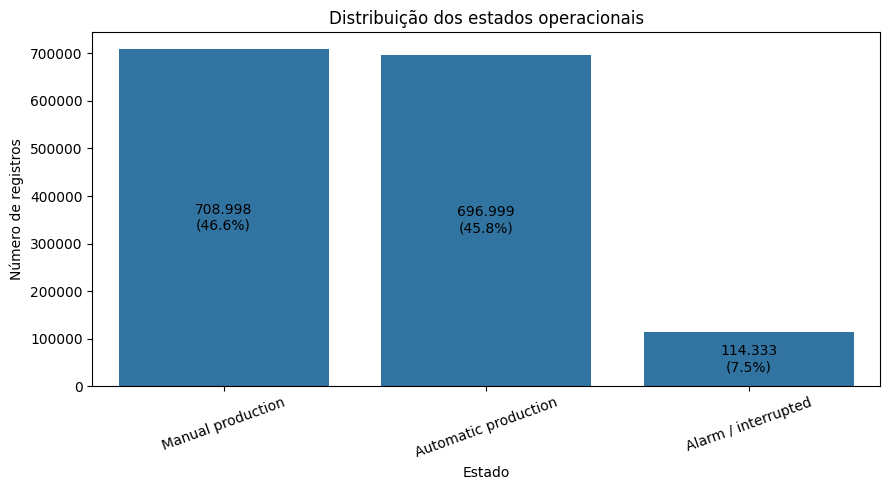

In [54]:
plt.figure(figsize=(9, 5))
ax = sns.countplot(
    data=df,
    x="status_label",
    order=df["status_label"].value_counts().index
)
plt.title("Distribuição dos estados operacionais")
plt.xlabel("Estado")
plt.ylabel("Número de registros")
plt.xticks(rotation=20)
# Add values and percentages inside the bars
total = len(df)
for bar in ax.patches:
    value = bar.get_height()
    percentage = 100 * value / total
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value / 2,
        f"{int(value):,}".replace(",", ".") + f"\n({percentage:.1f}%)",
        ha="center",
        va="center"
    )
plt.tight_layout()
plt.show()

## 5. Construção dos eventos de falha/interrupção

Um evento é definido como uma **entrada no estado 3**. Registros consecutivos em estado 3 pertencem ao mesmo evento.

Nesta base de dados também pode ser observado pela coluna "alarm" que será sempre 1 quando estiver em estado 3.

In [55]:
print("\nSTATUS_ALARM =", STATUS_ALARM)
print("Contagem de status:")
# contagem
print(df["status"].value_counts().sort_index())
# proporção
print(
    df["status"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)


print("\nContagem de alarm:")
# contagem
print(df["alarm"].value_counts(dropna=False))
# proporção
# proporção
print(
    df["alarm"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)
print("\nNote que Status=3 é equivavente a Alarm=1.")

print("\nExemplos de registros:")
display(
    df[["ts", "asset", "status", "alarm", "power_avg"]]
    .head(20)
)


STATUS_ALARM = 3
Contagem de status:
status
1.0000    708998
2.0000    696999
3.0000    114333
Name: count, dtype: int64
status
1.0000   46.6300
2.0000   45.8500
3.0000    7.5200
Name: proportion, dtype: float64

Contagem de alarm:
alarm
0    1405997
1     114333
Name: count, dtype: int64
alarm
0   92.4800
1    7.5200
Name: proportion, dtype: float64

Note que Status=3 é equivavente a Alarm=1.

Exemplos de registros:


,ts,asset,status,alarm,power_avg
0,2021-03-30 14:17:50+00:00,0,1.0000,0,0.0000
1,2021-03-30 14:26:34+00:00,0,2.0000,0,0.0000
2,2021-03-30 14:26:49+00:00,0,3.0000,1,0.0000
3,2021-03-30 14:26:55+00:00,0,1.0000,0,0.0000
4,2021-03-30 14:27:53+00:00,0,3.0000,1,0.0000
5,2021-03-30 14:27:58+00:00,0,1.0000,0,0.0000
6,2021-03-30 14:28:38+00:00,0,3.0000,1,0.0000
7,2021-03-30 14:28:44+00:00,0,1.0000,0,0.0000
8,2021-03-30 14:29:40+00:00,0,3.0000,1,0.0000
9,2021-03-30 14:29:45+00:00,0,1.0000,0,0.0000


In [56]:
# ---------------------------------------------------------
# 1. Ordenar os dados cronologicamente
# ---------------------------------------------------------
df = (
    df.sort_values(["asset", "ts"])
      .reset_index(drop=True)
)

# ---------------------------------------------------------
# 2. Identificar o início de cada evento de alarme
# ---------------------------------------------------------
previous_alarm = (
    df.groupby("asset", sort=False)["alarm"]
      .shift(1, fill_value=0)
)

df["failure_start"] = (
    (df["alarm"] == 1) &
    (previous_alarm == 0)
)

# ---------------------------------------------------------
# 3. Criar identificador dos eventos
# ---------------------------------------------------------
df["event_id"] = (
    df.groupby("asset", sort=False)["failure_start"]
      .cumsum()
)

# ---------------------------------------------------------
# 4. Selecionar os inícios dos eventos
# ---------------------------------------------------------
starts = df.loc[
    df["failure_start"],
    ["asset", "ts", "event_id"]
].copy()

starts = starts.rename(
    columns={"ts": "start"}
)

# ---------------------------------------------------------
# 5. Selecionar os registros que NÃO estão em alarme
# ---------------------------------------------------------
recoveries = df.loc[
    df["alarm"] == 0,
    ["asset", "ts"]
].copy()

recoveries = recoveries.rename(
    columns={"ts": "end"}
)

# ---------------------------------------------------------
# 6. Encontrar o primeiro não-alarme após cada início
# ---------------------------------------------------------
events = pd.merge_asof(
    starts.sort_values("start"),
    recoveries.sort_values("end"),
    left_on="start",
    right_on="end",
    by="asset",
    direction="forward",
    allow_exact_matches=False
)

# ---------------------------------------------------------
# 7. Adicionar informações dos registros em alarme
# ---------------------------------------------------------
alarm_df = df.loc[
    df["alarm"] == 1,
    ["asset", "event_id", "ts", "power_avg"]
].copy()

event_stats = (
    alarm_df
    .groupby(["asset", "event_id"], sort=False)
    .agg(
        records=("ts", "size"),
        avg_power=("power_avg", "mean"),
        max_power=("power_avg", "max")
    )
    .reset_index()
)

# ---------------------------------------------------------
# 8. Juntar estatísticas ao evento
# ---------------------------------------------------------
events = events.merge(
    event_stats,
    on=["asset", "event_id"],
    how="left"
)

# ---------------------------------------------------------
# 9. Calcular duração
# ---------------------------------------------------------
events["duration_min"] = (
    events["end"] - events["start"]
).dt.total_seconds() / 60

# ---------------------------------------------------------
# 10. Organizar resultado
# ---------------------------------------------------------
events = (
    events
    .sort_values(["asset", "start"])
    .reset_index(drop=True)
)
events = events.reindex(columns=[
    "asset",
    "start",
    "end",
    "event_id",
    "records",
    "duration_min",
    "avg_power",
    "max_power"
])

print(f"Eventos identificados: {len(events):,}")
# Reorder columns and display the first 10 events
display(events.head(10))

Eventos identificados: 34,858


,asset,start,end,event_id,records,duration_min,avg_power,max_power
0,0,2021-03-30 14:26:49+00:00,2021-03-30 14:26:55+00:00,1,1,0.1000,0.0000,0.0000
1,0,2021-03-30 14:27:53+00:00,2021-03-30 14:27:58+00:00,2,1,0.0833,0.0000,0.0000
2,0,2021-03-30 14:28:38+00:00,2021-03-30 14:28:44+00:00,3,1,0.1000,0.0000,0.0000
3,0,2021-03-30 14:29:40+00:00,2021-03-30 14:29:45+00:00,4,1,0.0833,0.0000,0.0000
4,0,2021-03-30 14:30:34+00:00,2021-03-30 14:30:40+00:00,5,1,0.1000,0.0000,0.0000
5,0,2021-03-30 14:32:32+00:00,2021-03-30 14:32:37+00:00,6,1,0.0833,0.0000,0.0000
6,0,2021-03-30 14:33:18+00:00,2021-03-30 14:33:23+00:00,7,1,0.0833,0.0000,0.0000
7,0,2021-03-30 14:34:21+00:00,2021-03-30 14:34:27+00:00,8,1,0.1000,0.0000,0.0000
8,0,2021-03-30 14:35:17+00:00,2021-03-30 14:35:22+00:00,9,1,0.0833,0.0000,0.0000
9,0,2021-03-30 14:36:10+00:00,2021-03-30 14:36:15+00:00,10,1,0.0833,0.0000,0.0000


## 6. Tempo entre falhas

O intervalo entre o início de cada evento de falha é utilizado como **TBF (Time Between Failures)**.

A duração observada do estado de alarme é usada como **TTR (Time to Repair)**.

In [57]:
events = events.sort_values(["asset", "start"]).copy()
events["next_failure_start"] = events.groupby("asset")["start"].shift(-1)
events["tbf_min"] = (
    events["next_failure_start"] - events["start"]
).dt.total_seconds().div(60)

# Renomeia a coluna
#events = events.rename(columns={"duration_min": "ttr_min"})

display(events[["asset", "start", "end", "duration_min", "tbf_min"]].head(15))

,asset,start,end,duration_min,tbf_min
0,0,2021-03-30 14:26:49+00:00,2021-03-30 14:26:55+00:00,0.1000,1.0667
1,0,2021-03-30 14:27:53+00:00,2021-03-30 14:27:58+00:00,0.0833,0.7500
2,0,2021-03-30 14:28:38+00:00,2021-03-30 14:28:44+00:00,0.1000,1.0333
3,0,2021-03-30 14:29:40+00:00,2021-03-30 14:29:45+00:00,0.0833,0.9000
4,0,2021-03-30 14:30:34+00:00,2021-03-30 14:30:40+00:00,0.1000,1.9667
5,0,2021-03-30 14:32:32+00:00,2021-03-30 14:32:37+00:00,0.0833,0.7667
6,0,2021-03-30 14:33:18+00:00,2021-03-30 14:33:23+00:00,0.0833,1.0500
7,0,2021-03-30 14:34:21+00:00,2021-03-30 14:34:27+00:00,0.1000,0.9333
8,0,2021-03-30 14:35:17+00:00,2021-03-30 14:35:22+00:00,0.0833,0.8833
9,0,2021-03-30 14:36:10+00:00,2021-03-30 14:36:15+00:00,0.0833,1.0667


tbf_min:
  Limite inferior: -28.12
  Limite superior: 49.54
  Registros removidos: 6426
duration_min:
  Limite inferior: -0.14
  Limite superior: 0.46
  Registros removidos: 4627

Resumo:
Registros originais: 34858
Registros após remoção: 23805
Total removido: 11053


,asset,start,end,duration_min,tbf_min
0,0,2021-03-30 14:26:49+00:00,2021-03-30 14:26:55+00:00,0.1000,1.0667
1,0,2021-03-30 14:27:53+00:00,2021-03-30 14:27:58+00:00,0.0833,0.7500
2,0,2021-03-30 14:28:38+00:00,2021-03-30 14:28:44+00:00,0.1000,1.0333
3,0,2021-03-30 14:29:40+00:00,2021-03-30 14:29:45+00:00,0.0833,0.9000
4,0,2021-03-30 14:30:34+00:00,2021-03-30 14:30:40+00:00,0.1000,1.9667
5,0,2021-03-30 14:32:32+00:00,2021-03-30 14:32:37+00:00,0.0833,0.7667
6,0,2021-03-30 14:33:18+00:00,2021-03-30 14:33:23+00:00,0.0833,1.0500
7,0,2021-03-30 14:34:21+00:00,2021-03-30 14:34:27+00:00,0.1000,0.9333
8,0,2021-03-30 14:35:17+00:00,2021-03-30 14:35:22+00:00,0.0833,0.8833
9,0,2021-03-30 14:36:10+00:00,2021-03-30 14:36:15+00:00,0.0833,1.0667



=== TBF ===


,tbf_min
count,"23,798.0000"
mean,5.0000
std,8.0400
min,0.1000
25%,0.9700
50%,1.9000
75%,5.1800
max,49.5200


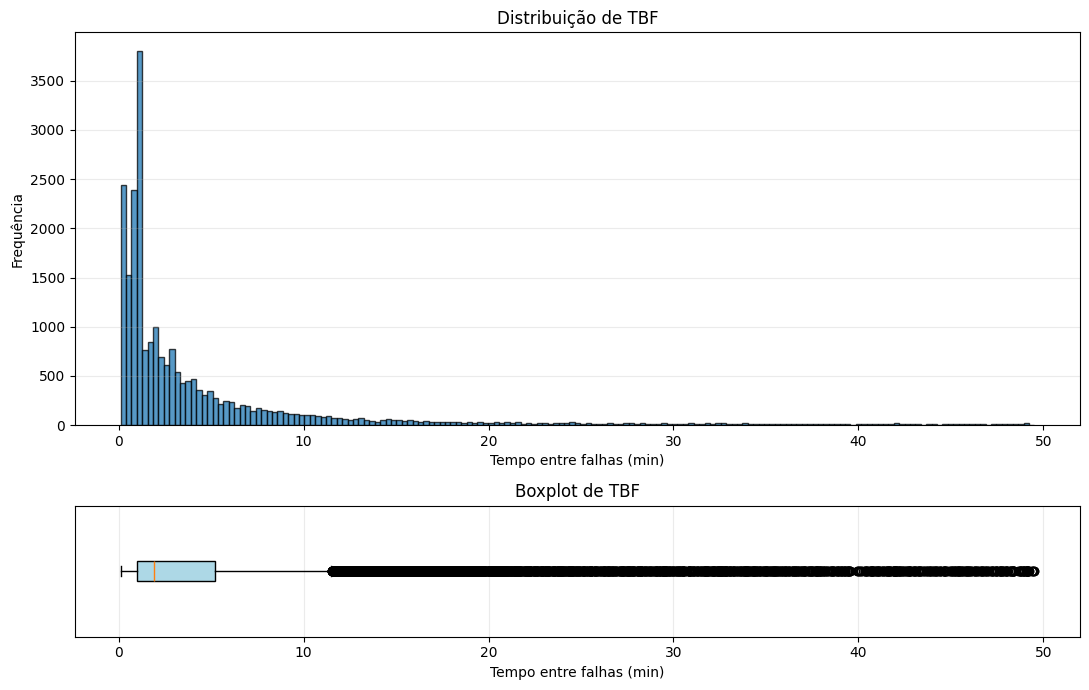


=== Duration ===


,duration_min
count,"23,803.0000"
mean,0.1200
std,0.0800
min,0.0200
25%,0.0800
50%,0.0800
75%,0.1200
max,0.4500


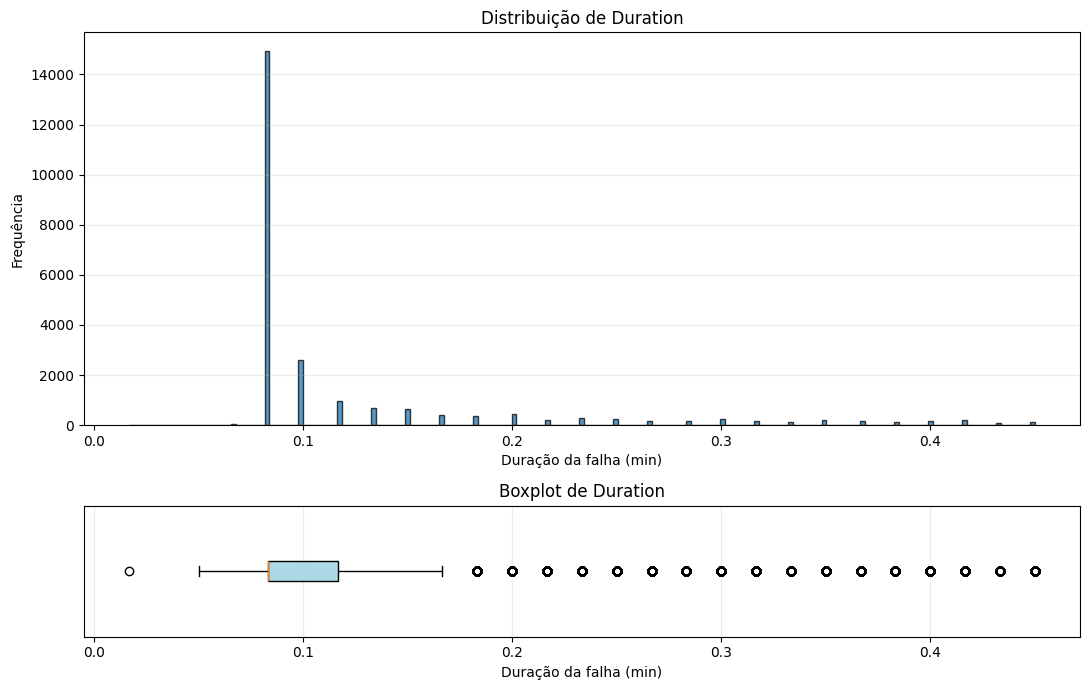

In [ ]:
# =========================================================
# CÓPIA DA BASE E REMOÇÃO DE OUTLIERS
# =========================================================

import numpy as np
import pandas as pd

# Create a copy of the original dataset
events_clean = events.copy()

columns = ["tbf_min", "duration_min"]

# Remove rows with outliers in either variable
for col in columns:
    q1 = events_clean[col].quantile(0.25)
    q3 = events_clean[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = ~events_clean[col].between(
        lower_bound, upper_bound
    ) & events_clean[col].notna()

    print(f"{col}:")
    print(f"  Limite inferior: {lower_bound:.2f}")
    print(f"  Limite superior: {upper_bound:.2f}")
    print(f"  Registros removidos: {outliers.sum()}")

    events_clean = events_clean.loc[~outliers].copy()

# Summary
print("\nResumo:")
print(f"Registros originais: {len(events)}")
print(f"Registros após remoção: {len(events_clean)}")
print(f"Total removido: {len(events) - len(events_clean)}")

display(
    events_clean[
        ["asset", "start", "end", "duration_min", "tbf_min"]
    ].head(15)
)


=== TBF ===


,tbf_min
count,"23,798.0000"
mean,5.0000
std,8.0400
min,0.1000
25%,0.9700
50%,1.9000
75%,5.1800
max,49.5200


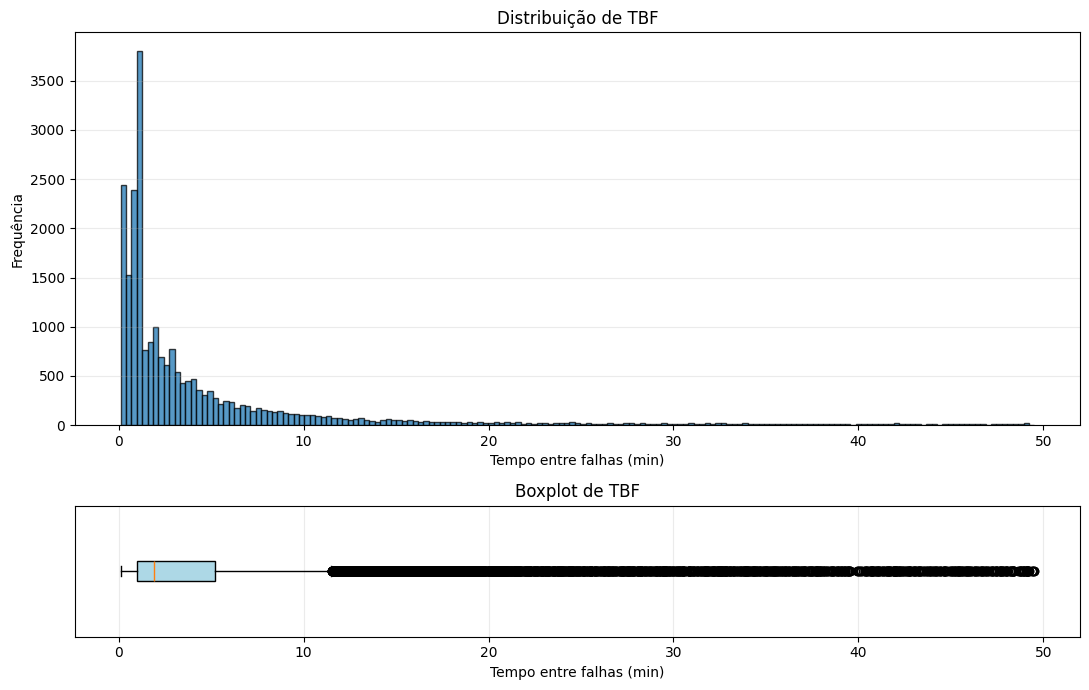


=== Duration ===


,duration_min
count,"23,803.0000"
mean,0.1200
std,0.0800
min,0.0200
25%,0.0800
50%,0.0800
75%,0.1200
max,0.4500


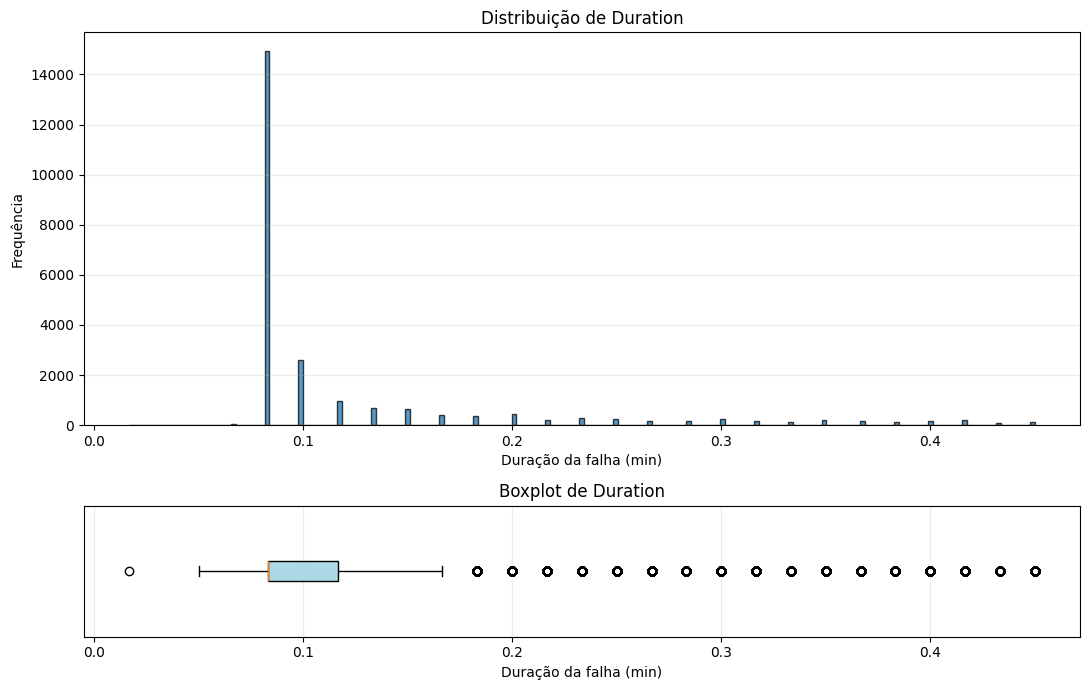

In [100]:
# =========================================================
# DISTRIBUIÇÃO DO TBF E DURATION
# Histogramas + Boxplots
# =========================================================

import numpy as np
import matplotlib.pyplot as plt

variables = [
    ("tbf_min", "Tempo entre falhas (min)", "TBF"),
    ("duration_min", "Duração da falha (min)", "Duration")
]

for col, xlabel, title in variables:

    # BASE DE DADOS ORIGINAL
    # data = events[col].replace([np.inf, -np.inf], np.nan).dropna()
    # BASE DE DADOS SEM OUTLIER
    data = events_clean[col].replace([np.inf, -np.inf], np.nan).dropna()
    data = data[data >= 0]

    if data.empty:
        print(f"Sem dados válidos para {col}.")
        continue

    # Statistics
    print(f"\n=== {title} ===")
    display(data.describe().to_frame(name=col).round(2))

    # Histogram + boxplot
    fig, axes = plt.subplots(
        2, 1,
        figsize=(11, 7),
        gridspec_kw={"height_ratios": [3, 1]}
    )

    # Histogram
    axes[0].hist(data, bins="auto", edgecolor="black", alpha=0.75)
    axes[0].set_title(f"Distribuição de {title}")
    axes[0].set_xlabel(xlabel)
    axes[0].set_ylabel("Frequência")
    axes[0].grid(axis="y", alpha=0.25)

    # Boxplot
    axes[1].boxplot(data, vert=False, patch_artist=True,
                    boxprops=dict(facecolor="lightblue"))
    axes[1].set_xlabel(xlabel)
    axes[1].set_yticks([])
    axes[1].grid(axis="x", alpha=0.25)
    axes[1].set_title(f"Boxplot de {title}")

    plt.tight_layout()
    plt.show()

## 7. Indicadores de confiabilidade

- **MTBF:** média dos TBF observados.
- **MTTR:** média da duração observada dos eventos.
- **Disponibilidade:** $ MTTF / (MTTF + MTTR)  =  (MTBF - MTTR) / MTBF$.
- **Labda:** Taxa de falha $(1/MTBF)$
- **R:** Confiabilidade $(e^{-Labda*t})$

Os indicadores devem ser interpretados considerando a definição de evento e as limitações do dataset.

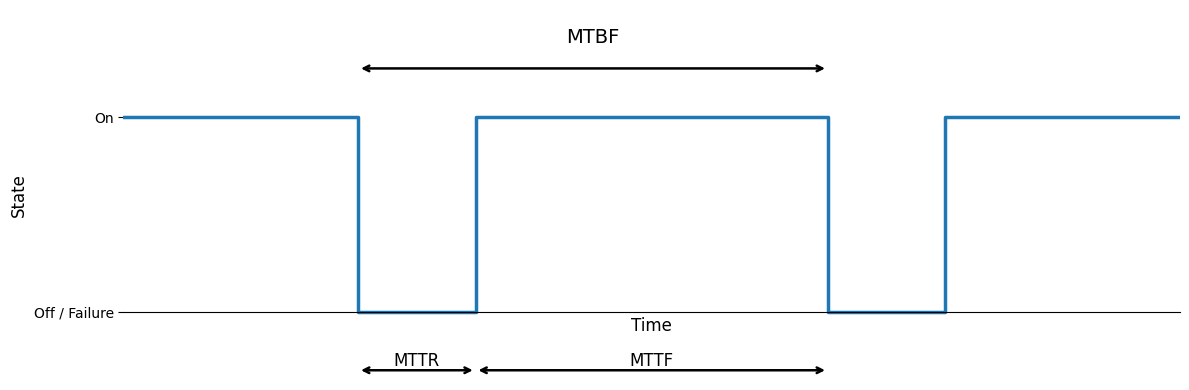

In [58]:
#IMAGEM ILUSTRATIVA

import matplotlib.pyplot as plt

# Time intervals (illustrative example)
time = [0, 2, 2, 3, 3, 6, 6, 7, 7, 9]
state = [1, 1, 0, 0, 1, 1, 0, 0, 1, 1]

fig, ax = plt.subplots(figsize=(12, 4))

# Operating / failure state
ax.step(time, state, where="post", linewidth=2.5)

# Hide default axes
ax.set_xticks([])
ax.set_yticks([0, 1])
ax.set_yticklabels(["Off / Failure", "On"])
ax.set_xlim(0, 9)
ax.set_ylim(-0.35, 1.55)

# Axis labels
ax.set_xlabel("Time", fontsize=12)
ax.set_ylabel("State", fontsize=12)

# MTBF: operating time between failures
ax.annotate(
    "",
    xy=(6, 1.25),
    xytext=(2, 1.25),
    arrowprops=dict(arrowstyle="<->", linewidth=1.8)
)
ax.text(4, 1.38, "MTBF", ha="center", fontsize=14)

# MTTR: repair duration during failure
ax.annotate(
    "",
    xy=(3, -0.3),
    xytext=(2, -0.3),
    arrowprops=dict(arrowstyle="<->", linewidth=1.8)
)
ax.text(2.5, -0.28, "MTTR", ha="center", fontsize=12)

# MTTF: time to failure
ax.annotate(
    "",
    xy=(6, -0.3),
    xytext=(3, -0.3),
    arrowprops=dict(arrowstyle="<->", linewidth=1.8)
)
ax.text(4.5, -0.28, "MTTF", ha="center", fontsize=12)

# Clean up chart
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_position(("data", 0))

plt.tight_layout()
plt.show()


In [64]:
valid_tbf = events[events["tbf_min"] > 0].copy()

kpi = (
    events.groupby("asset")
    .agg(
        failures=("event_id", "nunique"),
        total_alarm_min=("duration_min", "sum"),
        MTTR_min=("duration_min", "mean")
    )
    .reset_index()
)

mtbf = valid_tbf.groupby("asset")["tbf_min"].mean().rename("MTBF_min")
kpi = kpi.merge(mtbf, on="asset", how="left")

kpi["Availability_%"] = (
    #100 * kpi["MTBF_min"] / (kpi["MTBF_min"] + kpi["MTTR_min"])
    100 * (kpi["MTBF_min"] - kpi["MTTR_min"]) / (kpi["MTBF_min"]) # Duty Cycle
)
kpi["Failure_rate_per_h"] = 1 / (kpi["MTBF_min"]/60)
kpi = kpi.sort_values("Availability_%")

#display(kpi[["asset", "failures", "total_alarm_min", "MTTR_min", "MTBF_min", "Failure_rate_per_h", "Availability_%"]])
display(kpi)

,asset,failures,total_alarm_min,MTTR_min,MTBF_min,Availability_%,Failure_rate_per_h
0,0,4420,"180,336.7833",40.8094,185.4926,77.9994,0.3235
1,1,1261,"158,924.5500",126.1306,651.6323,80.6439,0.0921
2,2,16528,"33,509.2500",2.0274,49.4980,95.9040,1.2122
6,6,5371,"10,819.3500",2.0144,152.0543,98.6752,0.3946
4,4,2147,"10,131.0167",4.7187,379.9184,98.7580,0.1579
5,5,64,"6,711.0333",104.8599,"10,341.4161",98.9860,0.0058
3,3,2947,"2,218.7667",0.7529,277.5622,99.7287,0.2162
7,7,1048,981.6500,0.9367,790.3557,99.8815,0.0759
8,8,1072,700.3167,0.6533,772.4077,99.9154,0.0777


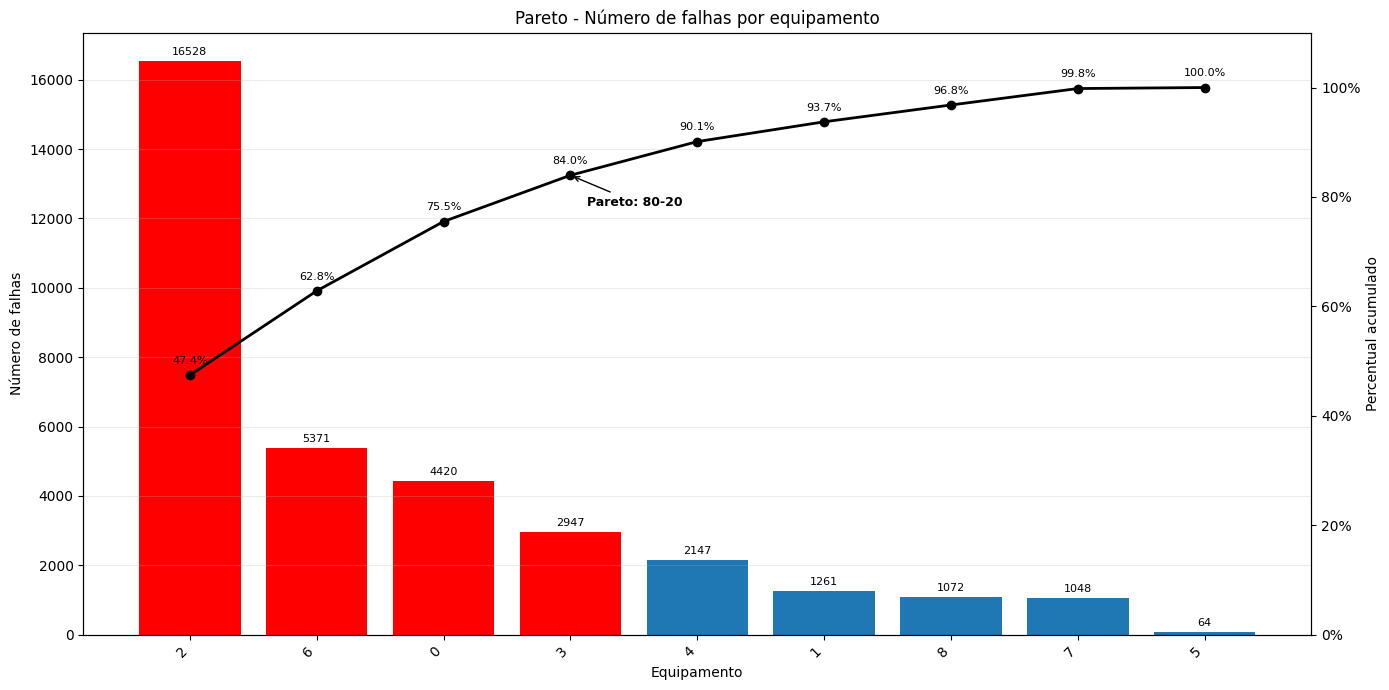

In [70]:
# =========================================================
#  NÚMERO DE FALHAS - GRÁFICO DE PARETO
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plot_data = kpi.sort_values("failures", ascending=False).copy()
plot_data = plot_data.reset_index(drop=True)

# Calculate cumulative percentage
total_failures = plot_data["failures"].sum()

if total_failures > 0:
    plot_data["cumulative_%"] = (
        plot_data["failures"].cumsum() / total_failures * 100
    )
else:
    plot_data["cumulative_%"] = 0

# Identify assets composing the first 80%
plot_data["critical_80"] = (
    plot_data["cumulative_%"].shift(fill_value=0) < 80
)

fig, ax1 = plt.subplots(figsize=(14, 7))

x = np.arange(len(plot_data))

# Bars
bar_colors = [
    "red" if critical else "C0"
    for critical in plot_data["critical_80"]
]

bars = ax1.bar(
    x,
    plot_data["failures"],
    color=bar_colors
)

ax1.set_title("Pareto - Número de falhas por equipamento")
ax1.set_xlabel("Equipamento")
ax1.set_ylabel("Número de falhas")
ax1.set_xticks(x)
ax1.set_xticklabels(plot_data["asset"].astype(str), rotation=45, ha="right")
ax1.grid(axis="y", alpha=0.25)

# Failure counts above bars
for bar in bars:
    height = bar.get_height()
    ax1.annotate(
        f"{height:.0f}",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Cumulative percentage line
ax2 = ax1.twinx()

ax2.plot(
    x,
    plot_data["cumulative_%"],
    marker="o",
    linewidth=2,
    color="black"
)

ax2.set_ylabel("Percentual acumulado")
ax2.set_ylim(0, 110)
ax2.yaxis.set_major_formatter(PercentFormatter(xmax=100))

# Percentage labels at every point
for i, value in enumerate(plot_data["cumulative_%"]):
    ax2.annotate(
        f"{value:.1f}%",
        (x[i], value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color="black"
    )

# Highlight where the cumulative percentage reaches 80%
if total_failures > 0 and (plot_data["cumulative_%"] >= 80).any():
    idx_80 = np.argmax(plot_data["cumulative_%"].to_numpy() >= 80)
    value_80 = plot_data["cumulative_%"].iloc[idx_80]

    ax2.annotate(
        "Pareto: 80-20",
        xy=(x[idx_80], value_80),
        xytext=(12, -22),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        arrowprops=dict(arrowstyle="->", color="black")
    )

plt.tight_layout()
plt.show()


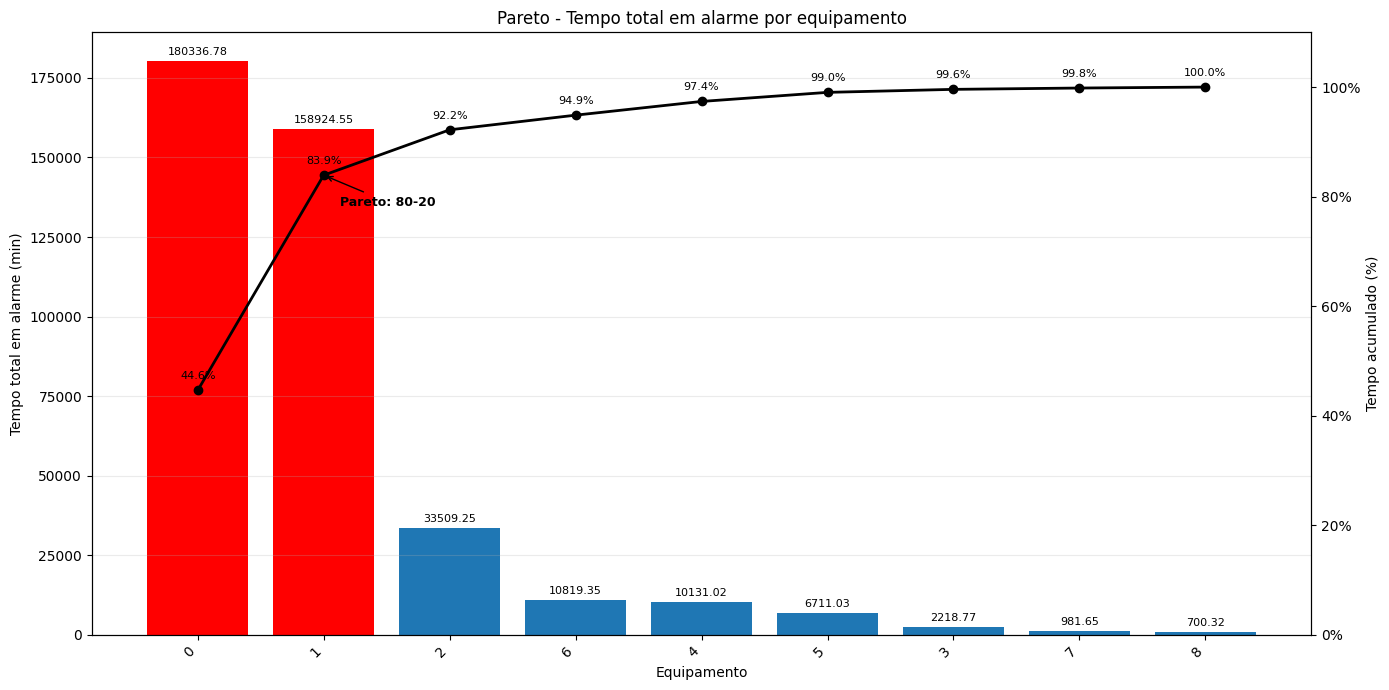

In [72]:
# =========================================================
#  TEMPO TOTAL EM ALARME - GRÁFICO DE PARETO
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Sort in descending order
plot_data = (
    kpi.sort_values("total_alarm_min", ascending=False)
    .reset_index(drop=True)
    .copy()
)

# Calculate cumulative percentage
total_alarm = plot_data["total_alarm_min"].sum()

if total_alarm > 0:
    plot_data["cumulative_%"] = (
        plot_data["total_alarm_min"].cumsum() / total_alarm * 100
    )
else:
    plot_data["cumulative_%"] = 0

# Identify assets composing the first 80%
plot_data["critical_80"] = (
    plot_data["cumulative_%"].shift(fill_value=0) < 80
)

fig, ax1 = plt.subplots(figsize=(14, 7))

x = np.arange(len(plot_data))

# Bars: red for the first 80%, blue for the remainder
bar_colors = [
    "red" if critical else "C0"
    for critical in plot_data["critical_80"]
]

bars = ax1.bar(
    x,
    plot_data["total_alarm_min"],
    color=bar_colors
)

ax1.set_title("Pareto - Tempo total em alarme por equipamento")
ax1.set_xlabel("Equipamento")
ax1.set_ylabel("Tempo total em alarme (min)")
ax1.set_xticks(x)
ax1.set_xticklabels(
    plot_data["asset"].astype(str),
    rotation=45,
    ha="right"
)
ax1.grid(axis="y", alpha=0.25)

# Display alarm time above bars
for bar in bars:
    height = bar.get_height()
    ax1.annotate(
        f"{height:.2f}",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Cumulative percentage line
ax2 = ax1.twinx()

ax2.plot(
    x,
    plot_data["cumulative_%"],
    marker="o",
    linewidth=2,
    color="black"
)

ax2.set_ylabel("Tempo acumulado (%)")
ax2.set_ylim(0, 110)
ax2.yaxis.set_major_formatter(PercentFormatter(xmax=100))

# Display cumulative percentage at every point
for i, value in enumerate(plot_data["cumulative_%"]):
    ax2.annotate(
        f"{value:.1f}%",
        (x[i], value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

# Mark where the cumulative percentage reaches 80%
if total_alarm > 0 and (plot_data["cumulative_%"] >= 80).any():
    idx_80 = np.argmax(
        plot_data["cumulative_%"].to_numpy() >= 80
    )

    ax2.annotate(
        "Pareto: 80-20",
        xy=(x[idx_80], plot_data["cumulative_%"].iloc[idx_80]),
        xytext=(12, -22),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        arrowprops=dict(arrowstyle="->", color="black")
    )

plt.tight_layout()
plt.show()

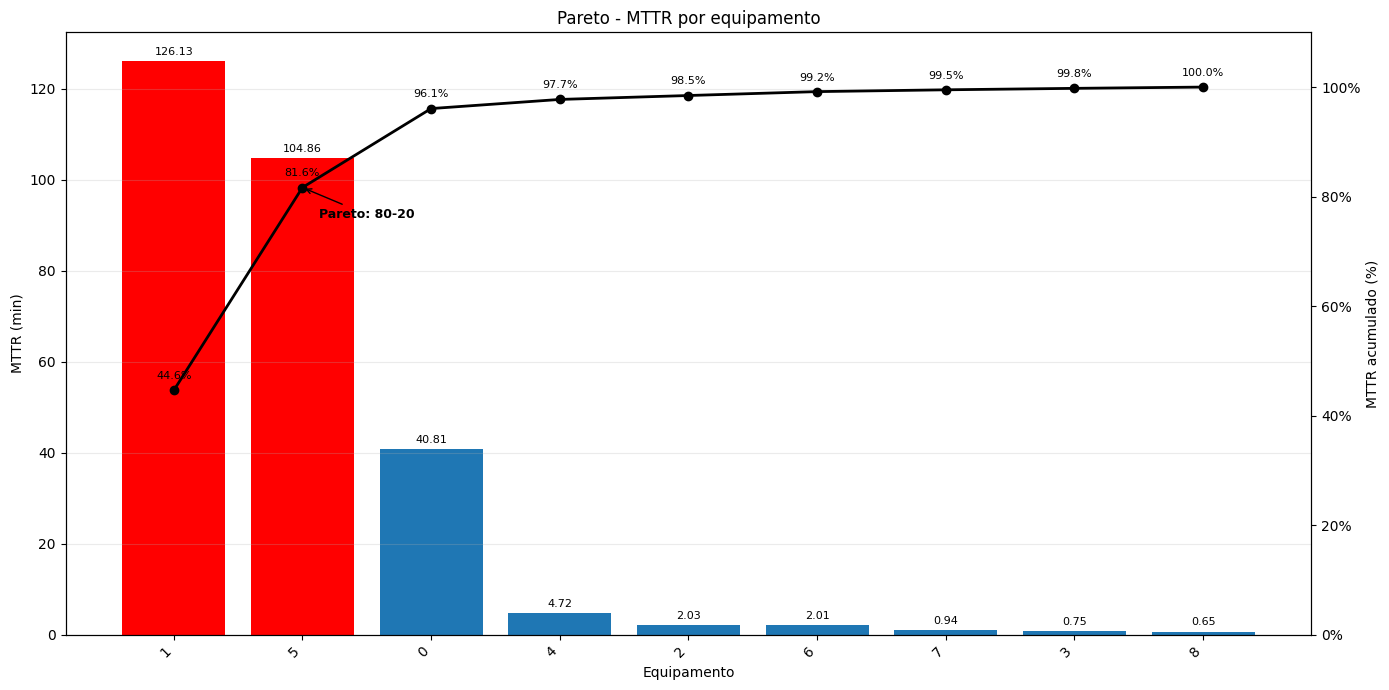

In [74]:
# =========================================================
#  MTTR - GRÁFICO DE PARETO
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Sort in descending order
plot_data = (
    kpi.sort_values("MTTR_min", ascending=False)
    .reset_index(drop=True)
    .copy()
)

# Calculate cumulative percentage
total_mttr = plot_data["MTTR_min"].sum()

if total_mttr > 0:
    plot_data["cumulative_%"] = (
        plot_data["MTTR_min"].cumsum() / total_mttr * 100
    )
else:
    plot_data["cumulative_%"] = 0

# Identify assets composing the first 80%
plot_data["critical_80"] = (
    plot_data["cumulative_%"].shift(fill_value=0) < 80
)

fig, ax1 = plt.subplots(figsize=(14, 7))

x = np.arange(len(plot_data))

# Bars
bar_colors = [
    "red" if critical else "C0"
    for critical in plot_data["critical_80"]
]

bars = ax1.bar(
    x,
    plot_data["MTTR_min"],
    color=bar_colors
)

ax1.set_title("Pareto - MTTR por equipamento")
ax1.set_xlabel("Equipamento")
ax1.set_ylabel("MTTR (min)")
ax1.set_xticks(x)
ax1.set_xticklabels(
    plot_data["asset"].astype(str),
    rotation=45,
    ha="right"
)
ax1.grid(axis="y", alpha=0.25)

# Display MTTR values above bars
for bar in bars:
    height = bar.get_height()
    ax1.annotate(
        f"{height:.2f}",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Cumulative percentage line
ax2 = ax1.twinx()

ax2.plot(
    x,
    plot_data["cumulative_%"],
    marker="o",
    linewidth=2,
    color="black"
)

ax2.set_ylabel("MTTR acumulado (%)")
ax2.set_ylim(0, 110)
ax2.yaxis.set_major_formatter(PercentFormatter(xmax=100))

# Display cumulative percentage at every point
for i, value in enumerate(plot_data["cumulative_%"]):
    ax2.annotate(
        f"{value:.1f}%",
        (x[i], value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

# Mark where the cumulative percentage reaches 80%
if total_mttr > 0 and (plot_data["cumulative_%"] >= 80).any():
    idx_80 = np.argmax(
        plot_data["cumulative_%"].to_numpy() >= 80
    )

    ax2.annotate(
        "Pareto: 80-20",
        xy=(x[idx_80], plot_data["cumulative_%"].iloc[idx_80]),
        xytext=(12, -22),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        arrowprops=dict(arrowstyle="->", color="black")
    )

plt.tight_layout()
plt.show()

Para MTBF e MTTF não se aplica a análise de Pareto, pois os pontos críticos são os menores valores.
    Neste caso pode ser analisada a distribuição em quartis ou avaliar a taxa de falha, que é definida por Labda = 1/MTBF


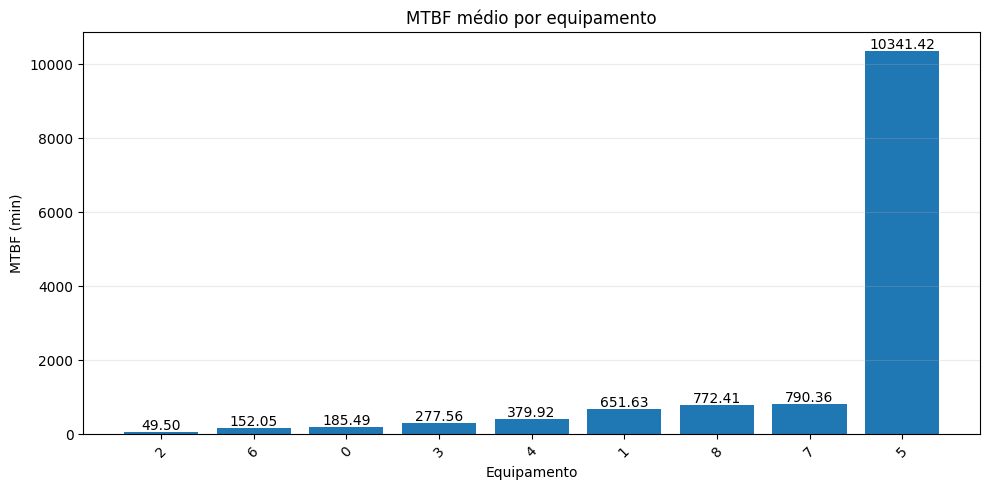

=== ANÁLISE DOS OUTLIERS DE MTBF ===
Q1: 185.49 min
Q3: 772.41 min
IQR: 586.92 min
Limite inferior: -694.88 min
Limite superior: 1652.78 min

Equipamentos removidos da visualização: 1


,asset,MTBF_min,Justificativa
8,5,"10,341.4161",MTBF acima do limite superior (1652.78 min)


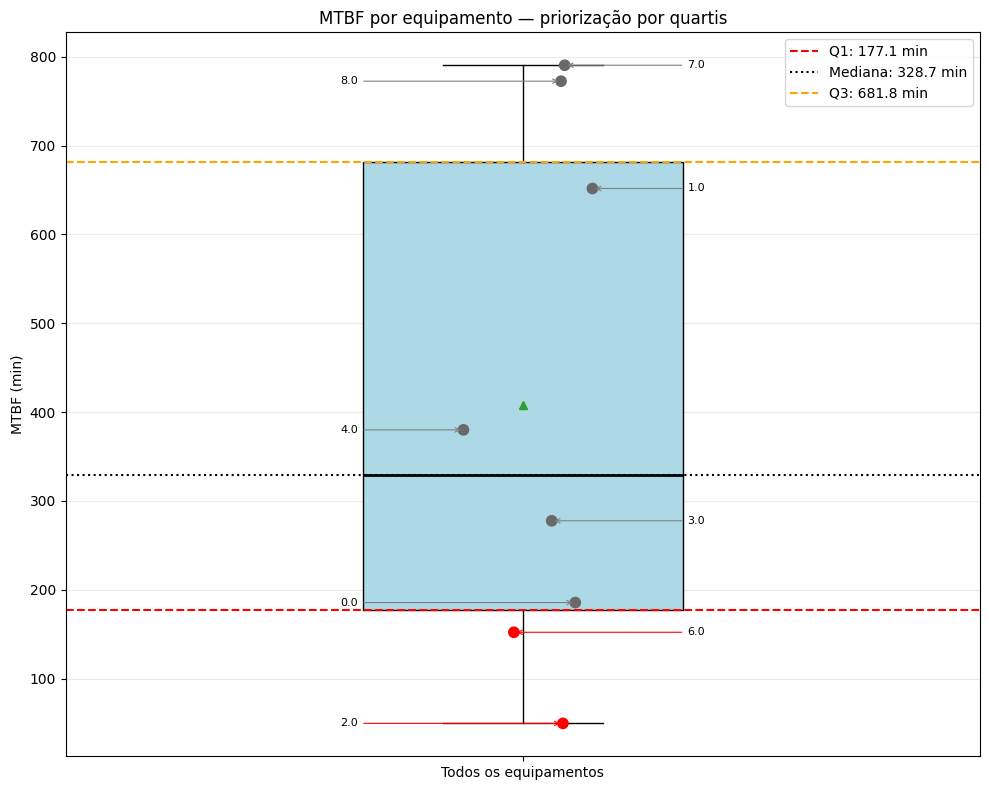

List critical equipment:


,asset,MTBF_min
0,2,49.4980
1,6,152.0543


In [95]:
# =========================================================
# 2. MTBF (não se aplica gráfico de Pareto)
# =========================================================

print('''Para MTBF e MTTF não se aplica a análise de Pareto, pois os pontos críticos são os menores valores.
    Neste caso pode ser analisada a distribuição em quartis ou avaliar a taxa de falha, que é definida por Labda = 1/MTBF''')

plt.figure(figsize=(10, 5))

plot_data = kpi.sort_values("MTBF_min")

bars = plt.bar(
    plot_data["asset"].astype(str),
    plot_data["MTBF_min"]
)

plt.title("MTBF médio por equipamento")
plt.xlabel("Equipamento")
plt.ylabel("MTBF (min)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.25)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()





# =========================================================
# 2. MTBF - BOXPLOT 
# =========================================================

import numpy as np
import matplotlib.pyplot as plt

# Prepare data and remove outliers using the IQR criterion
plot_data = (
    kpi.dropna(subset=["MTBF_min"])
    .sort_values("MTBF_min")
    .reset_index(drop=True)
    .copy()
)

q1_iqr = plot_data["MTBF_min"].quantile(0.25)
q3_iqr = plot_data["MTBF_min"].quantile(0.75)
iqr = q3_iqr - q1_iqr

lower_bound = q1_iqr - 1.5 * iqr
upper_bound = q3_iqr + 1.5 * iqr


# Identify outliers before filtering
outliers = plot_data[
    ~plot_data["MTBF_min"].between(lower_bound, upper_bound)
].copy()

# Display removed equipment and justification
print("=== ANÁLISE DOS OUTLIERS DE MTBF ===")
print(f"Q1: {q1_iqr:.2f} min")
print(f"Q3: {q3_iqr:.2f} min")
print(f"IQR: {iqr:.2f} min")
print(f"Limite inferior: {lower_bound:.2f} min")
print(f"Limite superior: {upper_bound:.2f} min")

if outliers.empty:
    print("\nNenhum outlier identificado pelo critério IQR.")
else:
    print(f"\nEquipamentos removidos da visualização: {len(outliers)}")

    outliers["Justificativa"] = outliers["MTBF_min"].apply(
        lambda x: (
            f"MTBF abaixo do limite inferior ({lower_bound:.2f} min)"
            if x < lower_bound
            else f"MTBF acima do limite superior ({upper_bound:.2f} min)"
        )
    )

    display(
        outliers[["asset", "MTBF_min", "Justificativa"]]
        .sort_values("MTBF_min")
    )

plot_data = plot_data[
    plot_data["MTBF_min"].between(lower_bound, upper_bound)
].reset_index(drop=True)

values = plot_data["MTBF_min"].to_numpy()

# Recalculate quartiles after removing outliers
q1, q2, q3 = np.percentile(values, [25, 50, 75])



fig, ax = plt.subplots(figsize=(10, 8))

# Vertical boxplot
ax.boxplot(
    values,
    vert=True,
    positions=[0],
    widths=0.35,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue"),
    medianprops=dict(color="black", linewidth=2),
    showmeans=True
)

# Equipment points
critical = plot_data["MTBF_min"] <= q1
colors = np.where(critical, "red", "dimgray")

rng = np.random.default_rng(42)
x_positions = rng.uniform(-0.08, 0.08, len(plot_data))

ax.scatter(
    x_positions,
    values,
    c=colors,
    s=55,
    zorder=3
)

# Equipment labels with arrows, alternating left and right
for i, row in plot_data.iterrows():
    x_text = -0.18 if i % 2 == 0 else 0.18
    align = "right" if i % 2 == 0 else "left"

    ax.annotate(
        str(row["asset"]),
        xy=(x_positions[i], row["MTBF_min"]),
        xytext=(x_text, row["MTBF_min"]),
        textcoords="data",
        ha=align,
        va="center",
        fontsize=8,
        arrowprops=dict(
            arrowstyle="->",
            color="red" if critical.iloc[i] else "gray",
            lw=0.8
        )
    )

# Quartile reference lines
ax.axhline(q1, color="red", linestyle="--", label=f"Q1: {q1:.1f} min")
ax.axhline(q2, color="black", linestyle=":", label=f"Mediana: {q2:.1f} min")
ax.axhline(q3, color="orange", linestyle="--", label=f"Q3: {q3:.1f} min")

ax.set_title("MTBF por equipamento — priorização por quartis")
ax.set_ylabel("MTBF (min)")
ax.set_xticks([0])
ax.set_xticklabels(["Todos os equipamentos"])
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()


print("List critical equipment:")
display(
    plot_data.loc[critical, ["asset", "MTBF_min"]]
    .sort_values("MTBF_min")
)

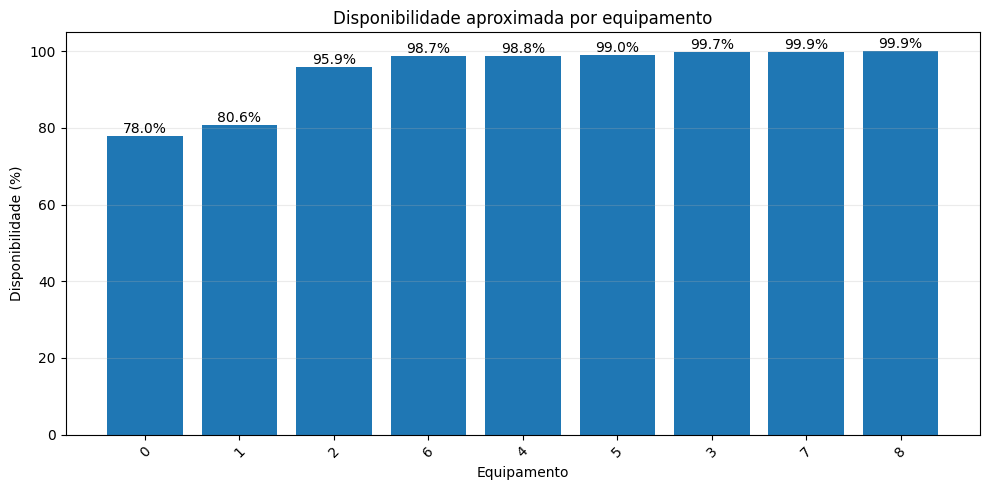

=== BOXPLOT DOS DADOS FILTRADOS ===
Q1: 95.90%
Mediana: 98.76%
Q3: 99.73%
Limite teórico inferior: 90.17%
Bigode inferior: 90.17%
Limite teórico superior: 105.47%
Bigode superior: 99.92%


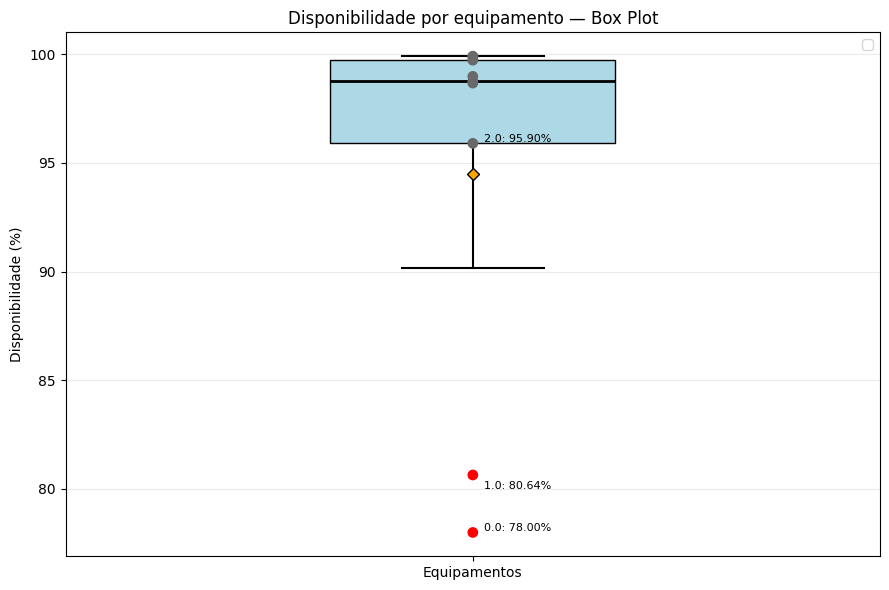

In [153]:

# =========================================================
# 1. AVAILABILITY
# =========================================================

plt.figure(figsize=(10, 5))

plot_data = kpi.sort_values("Availability_%")

bars = plt.bar(
    plot_data["asset"].astype(str),
    plot_data["Availability_%"]
)

plt.title("Disponibilidade aproximada por equipamento")
plt.xlabel("Equipamento")
plt.ylabel("Disponibilidade (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.25)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# =========================================================
# BOXPLOT — BIGODES E LIMITES CONSISTENTES
# =========================================================

# Quartiles calculated from the filtered data
values = plot_data["Availability_%"].to_numpy()

q1, median, q3 = np.percentile(values, [25, 50, 75])
iqr = q3 - q1

# IQR limits for the filtered data
lower_limit_plot = q1 - 1.5 * iqr
upper_limit_plot = q3 + 1.5 * iqr

# Actual whisker endpoints: extreme observed values within IQR limits
# whisker_low = values[values >= lower_limit_plot].min()
# whisker_high = values[values <= upper_limit_plot].max()

# Actual whisker endpoints: smallest and largest non-outlier values
# Whisker endpoints
whisker_low = (
    lower_limit_plot
    if values.min() < lower_limit_plot
    else values.min()
)

whisker_high = (
    upper_limit_plot
    if values.max() > upper_limit_plot
    else values.max()
)

print("=== BOXPLOT DOS DADOS FILTRADOS ===")
print(f"Q1: {q1:.2f}%")
print(f"Mediana: {median:.2f}%")
print(f"Q3: {q3:.2f}%")
print(f"Limite teórico inferior: {lower_limit_plot:.2f}%")
print(f"Bigode inferior: {whisker_low:.2f}%")
print(f"Limite teórico superior: {upper_limit_plot:.2f}%")
print(f"Bigode superior: {whisker_high:.2f}%")

fig, ax = plt.subplots(figsize=(9, 6))

# Explicit statistics ensure the box and whiskers match the printed values
stats = [{
    "label": "Equipamentos",
    "q1": q1,
    "med": median,
    "q3": q3,
    "whislo": whisker_low,
    "whishi": whisker_high,
    "mean": np.mean(values),
    "fliers": []
}]

ax.bxp(
    stats,
    positions=[1],
    widths=0.35,
    patch_artist=True,
    showmeans=True,
    showfliers=False,
    boxprops=dict(facecolor="lightblue"),
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color="black", linewidth=1.5),
    capprops=dict(color="black", linewidth=1.5),
    meanprops=dict(
        marker="D",
        markerfacecolor="orange",
        markeredgecolor="black",
        markersize=6
    )
)

# Equipment points
rng = np.random.default_rng(42)
# x_positions = rng.uniform(0.92, 1.08, len(plot_data))
x_positions = np.ones(len(plot_data))

colors = [
    "red" if v < lower_limit_plot or v > upper_limit_plot else "dimgray"
    for v in values
]

ax.scatter(
    x_positions,
    values,
    color=colors,
    s=45,
    zorder=3
)



# Equipment labels
for i, row in plot_data.iterrows():
    current_val = row['Availability_%']
    
    # Verifica se existe ALGUM OUTRO equipamento (diferente da linha atual 'i') 
    # cuja disponibilidade esteja no intervalo [current_val - 1, current_val + 1]
    overlap_condition = (
        (plot_data.index != i) & 
        (plot_data['Availability_%'] >= current_val - 1) & 
        (plot_data['Availability_%'] <= current_val + 1)
    ).any()
    
    # Se houver valores próximos, pula a anotação para evitar sobreposição
    if overlap_condition:
        continue
        
    ax.annotate(
        f"{row['asset']}: {current_val:.2f}%",
        xy=(x_positions[i], current_val),
        xytext=(8, 3 if i % 2 == 0 else -8),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=8
    )


ax.set_title("Disponibilidade por equipamento — Box Plot")
ax.set_ylabel("Disponibilidade (%)")
ax.set_xticks([1])
ax.set_xticklabels(["Equipamentos"])
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="best")

plt.tight_layout()
plt.show()

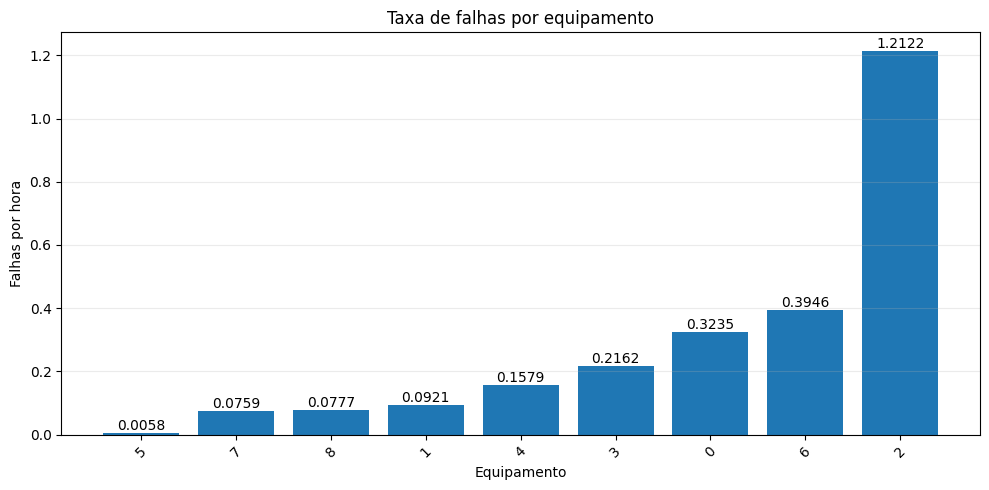

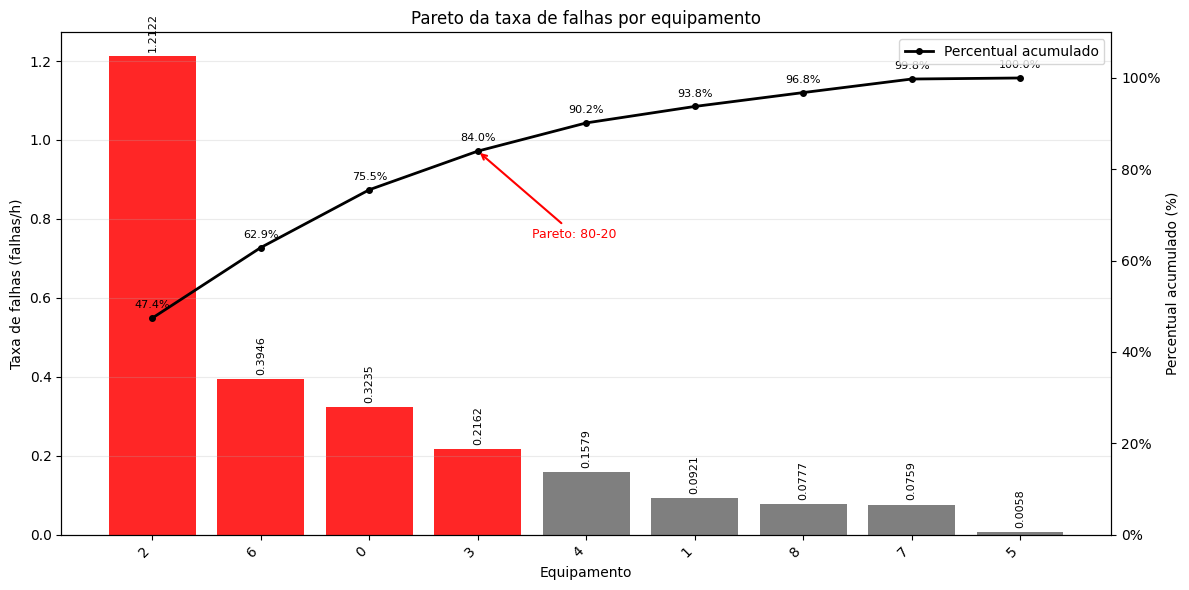

Equipamentos até o ponto de 80% acumulado:


,asset,Failure_rate_per_h,Cumulative_%
0,2,1.2122,47.4282
1,6,0.3946,62.8675
2,0,0.3235,75.5235
3,3,0.2162,83.9815


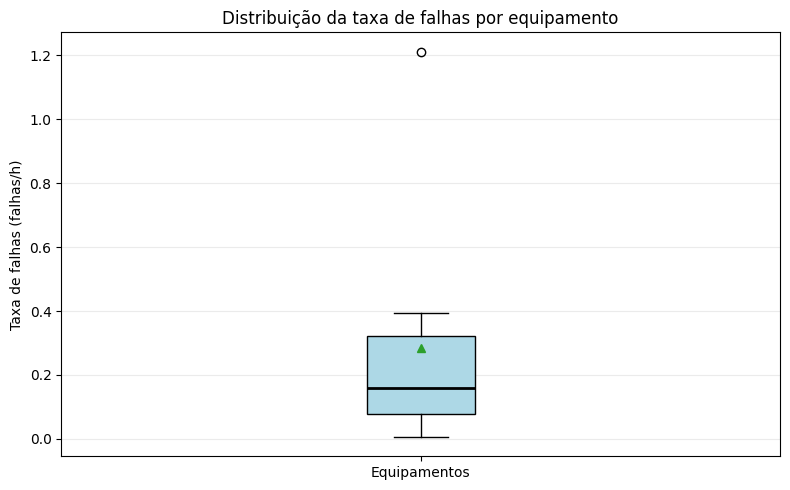

In [142]:

# =========================================================
# 6. TAXA DE FALHAS
# =========================================================

plt.figure(figsize=(10, 5))

plot_data = kpi.sort_values("Failure_rate_per_h")

bars = plt.bar(
    plot_data["asset"].astype(str),
    plot_data["Failure_rate_per_h"]
)

plt.title("Taxa de falhas por equipamento")
plt.xlabel("Equipamento")
plt.ylabel("Falhas por hora")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.25)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# =========================================================
# 6. PARETO — TAXA DE FALHAS
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Prepare data in descending order
plot_data = (
    kpi[["asset", "Failure_rate_per_h"]]
    .dropna()
    .sort_values("Failure_rate_per_h", ascending=False)
    .reset_index(drop=True)
    .copy()
)

total = plot_data["Failure_rate_per_h"].sum()

if total <= 0:
    print("Não é possível gerar o Pareto: a soma das taxas é zero ou negativa.")
else:
    # Cumulative percentage
    plot_data["Cumulative_%"] = (
        plot_data["Failure_rate_per_h"].cumsum() / total * 100
    )

    # Identify the equipment that reaches or exceeds 80%
    idx_80 = np.argmax(plot_data["Cumulative_%"].to_numpy() >= 80)
    plot_data["Pareto_group"] = np.where(
        np.arange(len(plot_data)) <= idx_80,
        "Até 80%",
        "Após 80%"
    )

    colors = np.where(
        np.arange(len(plot_data)) <= idx_80,
        "red",
        "dimgray"
    )

    fig, ax1 = plt.subplots(figsize=(12, 6))

    x = np.arange(len(plot_data))

    # Bars
    bars = ax1.bar(
        x,
        plot_data["Failure_rate_per_h"],
        color=colors,
        alpha=0.85
    )

    ax1.set_title("Pareto da taxa de falhas por equipamento")
    ax1.set_xlabel("Equipamento")
    ax1.set_ylabel("Taxa de falhas (falhas/h)")
    ax1.set_xticks(x)
    ax1.set_xticklabels(plot_data["asset"].astype(str), rotation=45, ha="right")
    ax1.grid(axis="y", alpha=0.25)

    # Bar value labels
    for bar in bars:
        height = bar.get_height()
        ax1.annotate(
            f"{height:.4f}",
            (bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

    # Cumulative percentage line
    ax2 = ax1.twinx()

    ax2.plot(
        x,
        plot_data["Cumulative_%"],
        color="black",
        marker="o",
        linewidth=2,
        markersize=4
    )

    ax2.set_ylabel("Percentual acumulado (%)")
    ax2.set_ylim(0, 110)
    ax2.yaxis.set_major_formatter(PercentFormatter(xmax=100))

    # Label cumulative percentage at each point
    for i, row in plot_data.iterrows():
        ax2.annotate(
            f"{row['Cumulative_%']:.1f}%",
            (i, row["Cumulative_%"]),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

    # Highlight the point where cumulative percentage reaches 80%
    ax2.annotate(
        f"Pareto: 80-20",
        xy=(idx_80, plot_data.loc[idx_80, "Cumulative_%"]),
        xytext=(idx_80 + 0.5, 65),
        textcoords="data",
        arrowprops=dict(arrowstyle="->", color="red", lw=1.5),
        color="red",
        fontsize=9,
        ha="left"
    )

    ax2.legend(
        ["Percentual acumulado"],
        loc="upper right",
        
    )

    plt.tight_layout()
    plt.show()

    print("Equipamentos até o ponto de 80% acumulado:")
    display(
        plot_data.loc[:idx_80, [
            "asset", "Failure_rate_per_h", "Cumulative_%"
        ]]
    )
    
    # =========================================================
# 6. BOXPLOT — TAXA DE FALHAS
# =========================================================

import matplotlib.pyplot as plt
import pandas as pd

plot_data = pd.to_numeric(
    kpi["Failure_rate_per_h"], errors="coerce"
).dropna()

plt.figure(figsize=(8, 5))

plt.boxplot(
    plot_data,
    vert=True,
    patch_artist=True,
    showmeans=True,
    showfliers=True,
    boxprops=dict(facecolor="lightblue"),
    medianprops=dict(color="black", linewidth=2)
)

plt.title("Distribuição da taxa de falhas por equipamento")
plt.ylabel("Taxa de falhas (falhas/h)")
plt.xticks([1], ["Equipamentos"])
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


## 9. Cálculo do OEE (Overall Equipment Effectiveness)

### 9.1 Fundamentação teórica

O OEE (Overall Equipment Effectiveness) é um indicador utilizado para avaliar a eficiência operacional dos equipamentos a partir de três componentes: disponibilidade, desempenho e qualidade. Conforme a abordagem apresentada por Hansen (2001), o indicador permite relacionar as perdas operacionais ao aproveitamento efetivo da capacidade produtiva.

O cálculo é realizado pelo produto dos três fatores:

$$
OEE = A \times P \times Q
$$

Em que:

- $A$: disponibilidade;
- $P$: desempenho;
- $Q$: qualidade.

### 9.2 Disponibilidade

A disponibilidade representa a proporção do tempo planejado para produção durante a qual o equipamento permaneceu operando:

$$
A = \frac{T_{\mathrm{op}}}{T_{\mathrm{plan}}}
$$

Em que $T_{\mathrm{op}}$ é o tempo de operação e $T_{\mathrm{plan}}$ é o tempo planejado de produção, descontadas as paradas planejadas conforme a regra adotada.

Para a base analisada, os estados de produção manual e automática serão considerados estados operacionais, enquanto o estado de alarme será tratado como uma possível interrupção. Neste caso será adotada a expressão utilizada anteriormente:

Disponibilidade = $ MTTF / (MTTF + MTTR) = (MTBF - MTTR) / MTBF$

### 9.3 Desempenho

O desempenho compara a quantidade produzida com a quantidade que poderia ter sido produzida durante o tempo de operação, considerando a taxa ideal de produção:

$$
P = \frac{N_{\mathrm{produzido}}}
{R_{\mathrm{ideal}} \times T_{\mathrm{op}}}
$$

Em que $N_{\mathrm{produzido}}$ representa a quantidade produzida e $R_{\mathrm{ideal}}$ corresponde à taxa ideal de produção por unidade de tempo.

### 9.4 Qualidade

A qualidade representa a proporção de unidades produzidas que atendem aos requisitos estabelecidos:

$$
Q = \frac{N_{\mathrm{boas}}}{N_{\mathrm{produzido}}}
$$

Em que $N_{\mathrm{boas}}$ corresponde à quantidade de unidades conformes.

### 9.5 Interpretação e limitações

O OEE completo somente será calculado quando houver dados suficientes para determinar os três componentes. Caso a base não contenha taxa ideal de produção ou quantidade de unidades conformes, serão apresentados apenas os indicadores que puderem ser calculados com os dados disponíveis.

Os resultados também dependem da identificação correta do tempo planejado de produção, da interpretação dos estados operacionais e da natureza da variável de produção. Assim, os valores obtidos deverão ser interpretados de acordo com as limitações da base utilizada.

**Referência:** HANSEN, Robert C. *Overall Equipment Effectiveness: A Powerful Production/Maintenance Tool for Increased Profits*. New York: Industrial Press, 2001.

In [61]:

# ============================================================
# 9. OEE calculation
# ============================================================

import numpy as np
import pandas as pd

# -------------------------
# Configuration
# -------------------------

TIMESTAMP_COL = "ts"#"timestamp"
ASSET_COL = "asset"
STATUS_COL = "status"
PRODUCTION_COL = "items"

# Replace with the actual column name if available.
GOOD_ITEMS_COL = "items" #"good_items" (in this case, all itens is good)

# Set the ideal production rate in items/hour.
# Use a single value for all assets or a dictionary by asset.
# Example: {"Machine_A": 1000, "Machine_B": 850}

#IDEAL_RATE_ITEMS_PER_HOUR = None
def estimate_ideal_production_rate(
    df,
    asset_col="asset",
    time_col="ts",
    status_col="status",
    production_col="items",
    automatic_status=2,
    percentile=0.95,
    max_interval_hours=1.0
):
    import pandas as pd

    data = df.copy()

    data[time_col] = pd.to_datetime(data[time_col], errors="coerce")
    data[production_col] = pd.to_numeric(data[production_col], errors="coerce")

    data = data.dropna(
        subset=[asset_col, time_col, status_col, production_col]
    ).sort_values([asset_col, time_col])

    data["interval_hours"] = (
        data.groupby(asset_col)[time_col]
        .shift(-1)
        .sub(data[time_col])
        .dt.total_seconds()
        .div(3600)
    )

    data = data[
        (data[status_col] == automatic_status)
        & (data["interval_hours"] > 0)
        & (data["interval_hours"] <= max_interval_hours)
        & (data[production_col] >= 0)
    ].copy()

    data["rate_items_hour"] = (
        data[production_col] / data["interval_hours"]
    )

    ideal_rate = (
        data.groupby(asset_col)["rate_items_hour"]
        .quantile(percentile)
    )

    return ideal_rate.to_dict()

IDEAL_RATE_ITEMS_PER_HOUR = estimate_ideal_production_rate(df)
print("\nEstimate ideal production rate:")
display(IDEAL_RATE_ITEMS_PER_HOUR,)

# Status definitions used in this notebook.
IDLE = 0
MANUAL = 1
AUTOMATIC = 2
ALARM = 3

OPERATING_STATUSES = [MANUAL, AUTOMATIC]

# -------------------------
# Validate and prepare data
# -------------------------

required = {
    TIMESTAMP_COL,
    ASSET_COL,
    STATUS_COL,
    PRODUCTION_COL
}

missing = required.difference(df.columns)

if missing:
    raise ValueError(
        f"Missing columns in df: {sorted(missing)}. "
        "Update the configuration to match your dataset."
    )

oee_data = df.copy()

oee_data[TIMESTAMP_COL] = pd.to_datetime(
    oee_data[TIMESTAMP_COL],
    errors="coerce"
)

oee_data = oee_data.dropna(
    subset=[TIMESTAMP_COL, ASSET_COL, STATUS_COL]
)

oee_data = oee_data.sort_values(
    [ASSET_COL, TIMESTAMP_COL]
).reset_index(drop=True)

oee_data[PRODUCTION_COL] = pd.to_numeric(
    oee_data[PRODUCTION_COL],
    errors="coerce"
).fillna(0).clip(lower=0)

# Assumption: each row's "items" value is production during
# that sampling interval, not a cumulative production counter.
# If it is cumulative, calculate interval differences first.

# -------------------------
# Estimate the duration represented by each row
# -------------------------

next_timestamp = (
    oee_data.groupby(ASSET_COL)[TIMESTAMP_COL].shift(-1)
)

interval_hours = (
    next_timestamp - oee_data[TIMESTAMP_COL]
).dt.total_seconds() / 3600

# Use the median sampling interval for the last row of each asset.
median_interval = (
    oee_data.assign(interval_hours=interval_hours)
    .groupby(ASSET_COL)["interval_hours"]
    .transform(
        lambda s: s[
            s.notna() & (s > 0)
        ].median()
    )
)

oee_data["interval_hours"] = interval_hours.where(
    interval_hours.notna() | (interval_hours > 0),
    median_interval
)

# Replace missing/non-positive durations with the asset median.
oee_data["interval_hours"] = oee_data[
    "interval_hours"
].where(
    oee_data["interval_hours"] > 0,
    median_interval
)

# Exclude unusually long gaps from being treated as continuous
# machine operation. Review this threshold for your dataset.
MAX_INTERVAL_HOURS = 1.0

oee_data["interval_hours"] = oee_data[
    "interval_hours"
].clip(upper=MAX_INTERVAL_HOURS)

# -------------------------
# Define planned production time
# -------------------------

# IMPORTANT:
# This assumes every row represents a period scheduled for
# production. If idle periods include breaks, weekends, or
# unscheduled time, replace this with an actual production
# schedule/mask before interpreting availability.

oee_data["planned_hours"] = oee_data["interval_hours"]

oee_data["operating_hours"] = np.where(
    oee_data[STATUS_COL].isin(OPERATING_STATUSES),
    oee_data["planned_hours"],
    0.0
)

oee_data["alarm_hours"] = np.where(
    oee_data[STATUS_COL] == ALARM,
    oee_data["planned_hours"],
    0.0
)

# -------------------------
# Aggregate indicators by asset
# -------------------------

oee = (
    oee_data.groupby(ASSET_COL)
    .agg(
        planned_hours=("planned_hours", "sum"),
        operating_hours=("operating_hours", "sum"),
        alarm_hours=("alarm_hours", "sum"),
        total_items=(PRODUCTION_COL, "sum")
    )
    .reset_index()
)

oee["Availability_%"] = np.where(
    oee["planned_hours"] > 0,
    100 * oee["operating_hours"] / oee["planned_hours"],
    np.nan
)

# -------------------------
# Calculate performance, quality and OEE if possible
# -------------------------

oee["Performance_%"] = np.nan
oee["Quality_%"] = np.nan
oee["OEE_%"] = np.nan

# Performance requires a known ideal production rate.
if IDEAL_RATE_ITEMS_PER_HOUR is not None:

    if isinstance(IDEAL_RATE_ITEMS_PER_HOUR, dict):
        ideal_rate = oee[ASSET_COL].map(
            IDEAL_RATE_ITEMS_PER_HOUR
        )
    else:
        ideal_rate = pd.Series(
            IDEAL_RATE_ITEMS_PER_HOUR,
            index=oee.index,
            dtype=float
        )

    ideal_capacity = ideal_rate * oee["operating_hours"]

    oee["Performance_%"] = np.where(
        ideal_capacity > 0,
        100 * oee["total_items"] / ideal_capacity,
        np.nan
    )

   

# Quality requires an actual count of good units.
if GOOD_ITEMS_COL in oee_data.columns:

    oee_data[GOOD_ITEMS_COL] = pd.to_numeric(
        oee_data[GOOD_ITEMS_COL],
        errors="coerce"
    ).fillna(0).clip(lower=0)

    good = (
        oee_data.groupby(ASSET_COL)[GOOD_ITEMS_COL]
        .sum()
        .rename("good_items")
        .reset_index()
    )

    oee = oee.merge(good, on=ASSET_COL, how="left")

    oee["Quality_%"] = np.where(
        oee["total_items"] > 0,
        100 * oee["good_items"] / oee["total_items"],
        np.nan
    )

# OEE is only valid when all three factors are available.
valid_oee = oee[
    ["Availability_%", "Performance_%", "Quality_%"]
].notna().all(axis=1)

oee.loc[valid_oee, "OEE_%"] = (
    oee.loc[valid_oee, "Availability_%"]
    * oee.loc[valid_oee, "Performance_%"]
    * oee.loc[valid_oee, "Quality_%"]
    / 10000
)

# -------------------------
# Display and export
# -------------------------
oee = oee.reindex(columns=[
    "asset",
    "operating_hours",
    "alarm_hours",
    "total_items",
    "planned_hours",
    "Availability_%",
    "Performance_%",
    "Quality_%",
    "OEE_%"
])

# Display without the good_items column
display(
    oee.drop(columns=["good_items"], errors="ignore")
       .sort_values("Availability_%", ascending=True)
)

from pathlib import Path

output_dir = Path("resultados_tcc")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "oee_por_equipamento.csv"
oee.to_csv(output_file, index=False, encoding="utf-8-sig")

print(f"Results exported to: {output_file.resolve()}")

if IDEAL_RATE_ITEMS_PER_HOUR is None:
    print(
        "Performance and OEE were not calculated: "
        "define the ideal production rate."
    )

if GOOD_ITEMS_COL not in oee_data.columns:
    print(
        "Quality and OEE were not calculated: "
        "provide a column with the number of good units."
    )


Estimate ideal production rate:


{0: 48.0,
 1: 60.0,
 2: 132.0,
 3: 120.0,
 4: 156.0,
 5: 72.0,
 6: 36.0,
 7: 60.0,
 8: 48.0}

,asset,operating_hours,alarm_hours,total_items,planned_hours,Availability_%,Performance_%,Quality_%,OEE_%
0,0,"10,519.0269","3,044.6969","198,735.0000","13,563.7239",77.5526,39.3602,100.0000,30.5249
1,1,"10,935.6808","2,720.9772","195,781.0000","13,656.6581",80.0758,29.8383,100.0000,23.8932
2,2,"12,109.8394",553.9064,"503,160.0000","12,663.7458",95.6260,31.4770,100.0000,30.1002
6,6,"12,997.1367",180.3225,"133,526.0000","13,177.4592",98.6316,28.5375,100.0000,28.1470
5,5,"12,120.6461",111.8506,"396,723.0000","12,232.4967",99.0856,45.4600,100.0000,45.0443
4,4,"11,351.6275",104.5161,"752,754.0000","11,456.1436",99.0877,42.5080,100.0000,42.1202
3,3,"12,660.0439",29.4781,"553,079.0000","12,689.5219",99.7677,36.4058,100.0000,36.3212
7,7,"12,872.6311",12.0231,"280,662.0000","12,884.6542",99.9067,36.3383,100.0000,36.3044
8,8,"13,483.9161",11.6719,"257,459.0000","13,495.5881",99.9135,39.7787,100.0000,39.7443


Results exported to: C:\Users\Keslley\Downloads\resultados_tcc\oee_por_equipamento.csv


## 8. Análise temporal das falhas

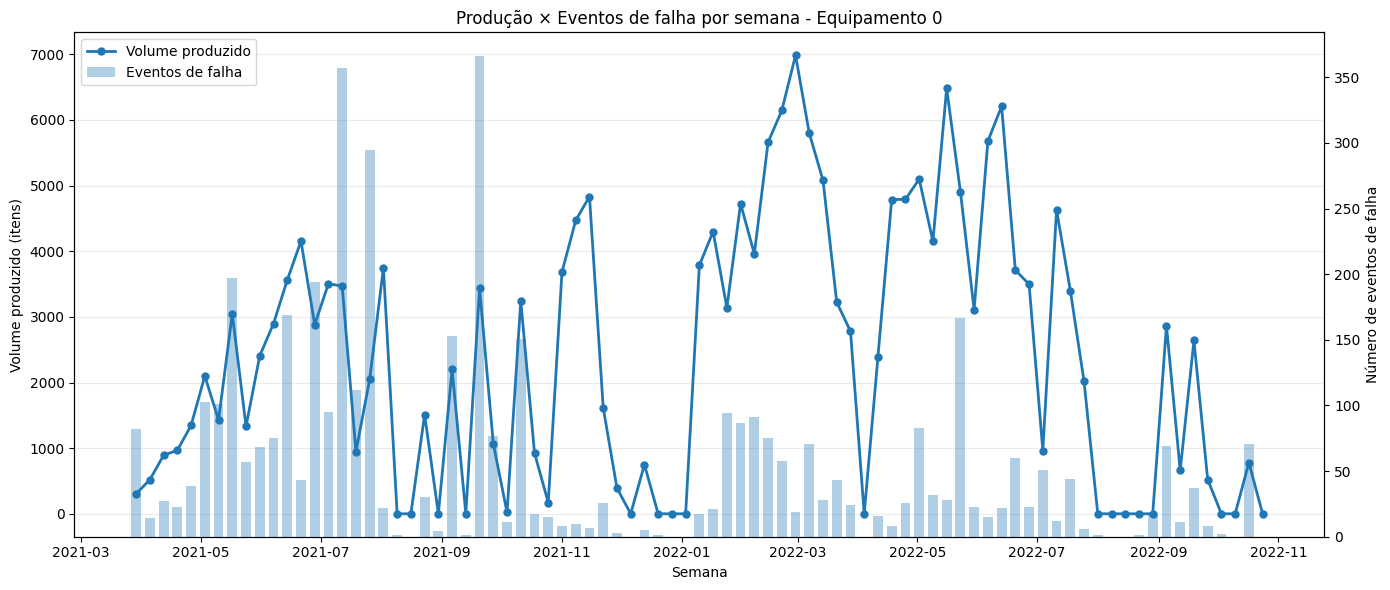

KeyError: 'hour'

In [62]:
# =========================================================
# PRODUÇÃO × EVENTOS DE FALHA
# ANÁLISE SEMANAL E POR HORA
# =========================================================

df["date"] = df["ts"].dt.date
events["date"] = events["start"].dt.date
events["hour"] = events["start"].dt.hour

assets = events["asset"].unique()

for asset in assets:

    asset_data = df[df["asset"] == asset].copy()
    asset_events = events[events["asset"] == asset].copy()

    asset_data["date"] = pd.to_datetime(asset_data["date"])
    asset_events["date"] = pd.to_datetime(asset_events["date"])

    # =====================================================
    # 1. ANÁLISE SEMANAL
    # =====================================================

    weekly_production = (
        asset_data
        .set_index("date")
        .resample("W-MON", label="left", closed="left")["items"]
        .sum()
        .rename("production")
    )

    weekly_failures = (
        asset_events
        .set_index("date")
        .resample("W-MON", label="left", closed="left")
        .size()
        .rename("failures")
    )

    weekly_analysis = pd.concat(
        [
            weekly_production,
            weekly_failures
        ],
        axis=1
    ).fillna(0)

    weekly_analysis = weekly_analysis.sort_index()

    # -----------------------------------------------------
    # Gráfico semanal
    # -----------------------------------------------------

    fig, ax1 = plt.subplots(figsize=(14, 6))

    ax1.plot(
        weekly_analysis.index,
        weekly_analysis["production"],
        marker="o",
        markersize=5,
        linewidth=2,
        label="Volume produzido"
    )

    ax1.set_xlabel("Semana")
    ax1.set_ylabel("Volume produzido (itens)")

    ax2 = ax1.twinx()

    ax2.bar(
        weekly_analysis.index,
        weekly_analysis["failures"],
        width=5,
        alpha=0.35,
        label="Eventos de falha"
    )

    ax2.set_ylabel("Número de eventos de falha")

    plt.title(
        f"Produção × Eventos de falha por semana - Equipamento {asset}"
    )

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="upper left"
    )

    ax1.grid(
        axis="y",
        alpha=0.25
    )

    fig.tight_layout()
    plt.show()


    # =====================================================
    # 2. ANÁLISE POR HORA
    # =====================================================

    hourly_production = (
        asset_data
        .groupby("hour")["items"]
        .sum()
        .rename("production")
    )

    hourly_failures = (
        asset_events
        .groupby("hour")
        .size()
        .rename("failures")
    )

    hourly_analysis = pd.concat(
        [
            hourly_production,
            hourly_failures
        ],
        axis=1
    ).fillna(0)

    # Garante todas as 24 horas
    hourly_analysis = hourly_analysis.reindex(
        range(24),
        fill_value=0
    )

    # -----------------------------------------------------
    # Gráfico por hora
    # -----------------------------------------------------

    fig, ax1 = plt.subplots(figsize=(12, 6))

    ax1.plot(
        hourly_analysis.index,
        hourly_analysis["production"],
        marker="o",
        linewidth=2,
        label="Volume produzido"
    )

    ax1.set_xlabel("Hora do dia")
    ax1.set_ylabel("Volume produzido (itens)")
    ax1.set_xticks(range(24))

    ax2 = ax1.twinx()

    ax2.bar(
        hourly_analysis.index,
        hourly_analysis["failures"],
        alpha=0.35,
        width=0.7,
        label="Eventos de falha"
    )

    ax2.set_ylabel("Número de eventos de falha")

    plt.title(
        f"Produção × Eventos de falha por hora - Equipamento {asset}"
    )

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="upper left"
    )

    ax1.grid(
        axis="y",
        alpha=0.25
    )

    fig.tight_layout()
    plt.show()

## 11. Análise de pré-falha

Cada evento é comparado com uma janela anterior ao início do alarme. O padrão inicial é 30 minutos.

In [ ]:
PRE_FAILURE_MINUTES = 30

pre_failure_rows = []

for asset, asset_events in events.groupby("asset"):
    asset_data = df[df["asset"].eq(asset)]
    for _, event in asset_events.iterrows():
        start = event["start"]
        window = asset_data[
            (asset_data["ts"] >= start - pd.Timedelta(minutes=PRE_FAILURE_MINUTES)) &
            (asset_data["ts"] < start)
        ]

        if len(window):
            pre_failure_rows.append({
                "asset": asset,
                "event_id": event["event_id"],
                "pre_avg_power": window["power_avg"].mean(),
                "pre_max_power": window["power_avg"].max(),
                "pre_avg_items": window["items"].mean(),
                "pre_total_items": window["items"].sum(),
                "samples": len(window)
            })

pre_failure = pd.DataFrame(pre_failure_rows)

print("Eventos com janela disponível:", len(pre_failure))
display(pre_failure.head())

Eventos com janela disponível: 34789


,asset,event_id,pre_avg_power,pre_max_power,pre_avg_items,pre_total_items,samples
0,0,1,0.0000,0.0000,0.0000,0.0000,2
1,0,2,0.0000,0.0000,0.0000,0.0000,4
2,0,3,0.0000,0.0000,0.3333,2.0000,6
3,0,4,0.0000,0.0000,0.2500,2.0000,8
4,0,5,0.0000,0.0000,0.3636,4.0000,11


In [ ]:
normal = df[df["status"].isin([STATUS_MANUAL, STATUS_AUTO])]

comparison = pd.DataFrame({
    "Normal_operation": [
        normal["power_avg"].mean(),
        normal["items"].mean()
    ],
    "Pre_failure_window": [
        pre_failure["pre_avg_power"].mean(),
        pre_failure["pre_avg_items"].mean()
    ]
}, index=["Average power (kW)", "Average items per record"])

display(comparison)

,Normal_operation,Pre_failure_window
Average power (kW),28.6179,90.0403
Average items per record,2.2925,1.8519


## 11. Distribuição dos tempos entre falhas

A distribuição exponencial é usada como primeira referência estatística. Para uma análise de confiabilidade mais robusta, a distribuição de Weibull também será ajustada.


Equipamento: 0
Número de TBF: 4419
Parâmetro de escala da distribuição: 3.092 h
Locação: 0.000 min
Teste KS: estatística = 0.5348
Teste KS: p-valor = 0.0000
Resultado: o ajuste exponencial é rejeitado ao nível de significância de 5%.


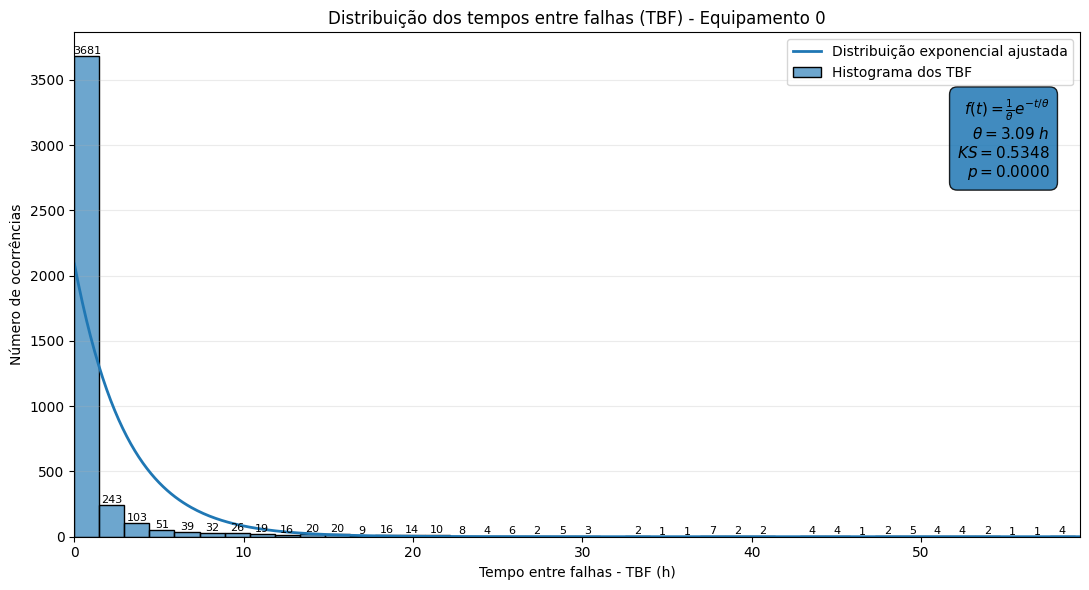


Equipamento: 1
Número de TBF: 1260
Parâmetro de escala da distribuição: 10.861 h
Locação: 0.000 min
Teste KS: estatística = 0.5982
Teste KS: p-valor = 0.0000
Resultado: o ajuste exponencial é rejeitado ao nível de significância de 5%.


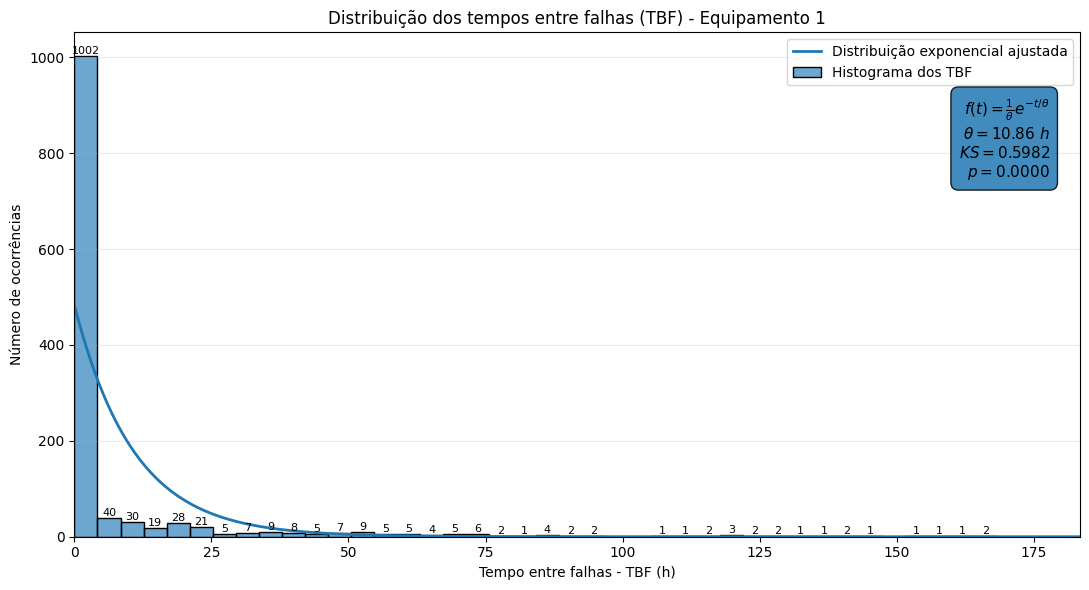


Equipamento: 2
Número de TBF: 16527
Parâmetro de escala da distribuição: 0.825 h
Locação: 0.000 min
Teste KS: estatística = 0.6635
Teste KS: p-valor = 0.0000
Resultado: o ajuste exponencial é rejeitado ao nível de significância de 5%.


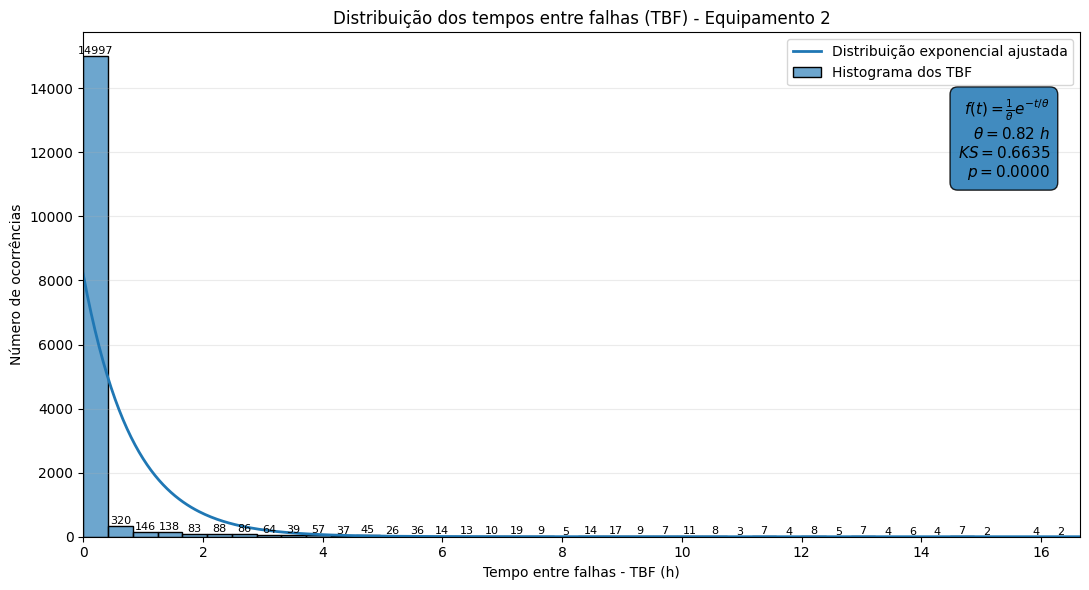


Equipamento: 3
Número de TBF: 2946
Parâmetro de escala da distribuição: 4.626 h
Locação: 0.000 min
Teste KS: estatística = 0.4824
Teste KS: p-valor = 0.0000
Resultado: o ajuste exponencial é rejeitado ao nível de significância de 5%.


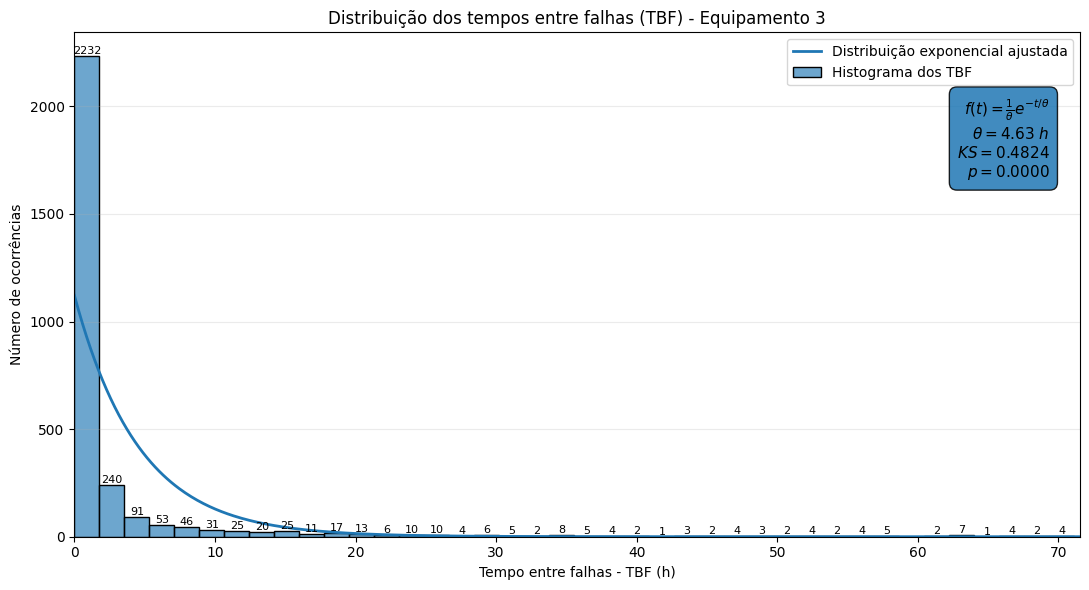


Equipamento: 4
Número de TBF: 2146
Parâmetro de escala da distribuição: 6.332 h
Locação: 0.000 min
Teste KS: estatística = 0.5556
Teste KS: p-valor = 0.0000
Resultado: o ajuste exponencial é rejeitado ao nível de significância de 5%.


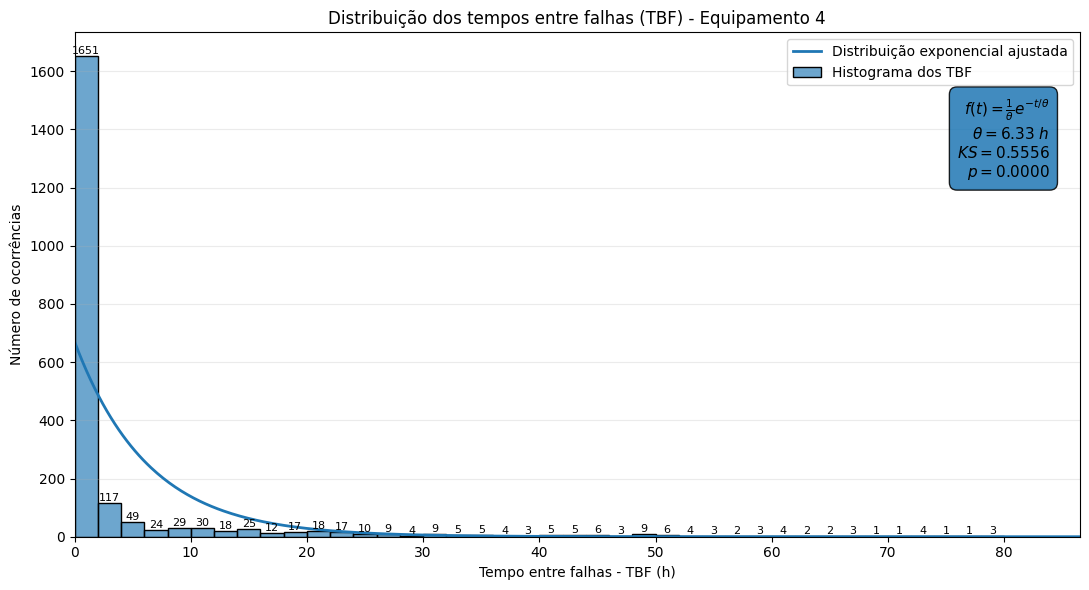


Equipamento: 5
Número de TBF: 63
Parâmetro de escala da distribuição: 172.357 h
Locação: 0.000 min
Teste KS: estatística = 0.6127
Teste KS: p-valor = 0.0000
Resultado: o ajuste exponencial é rejeitado ao nível de significância de 5%.


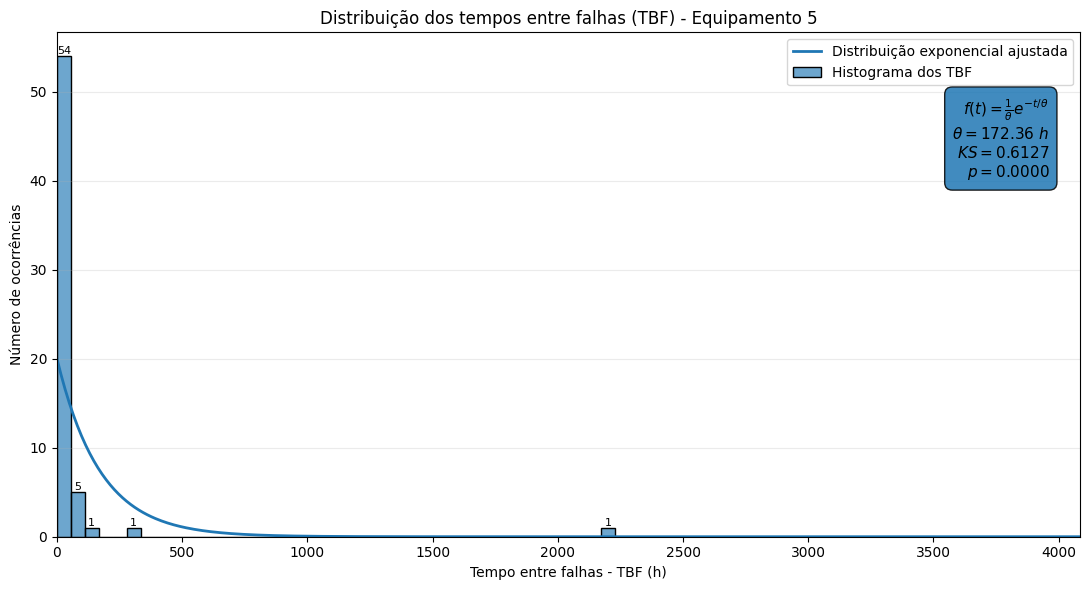


Equipamento: 6
Número de TBF: 5370
Parâmetro de escala da distribuição: 2.534 h
Locação: 0.000 min
Teste KS: estatística = 0.6752
Teste KS: p-valor = 0.0000
Resultado: o ajuste exponencial é rejeitado ao nível de significância de 5%.


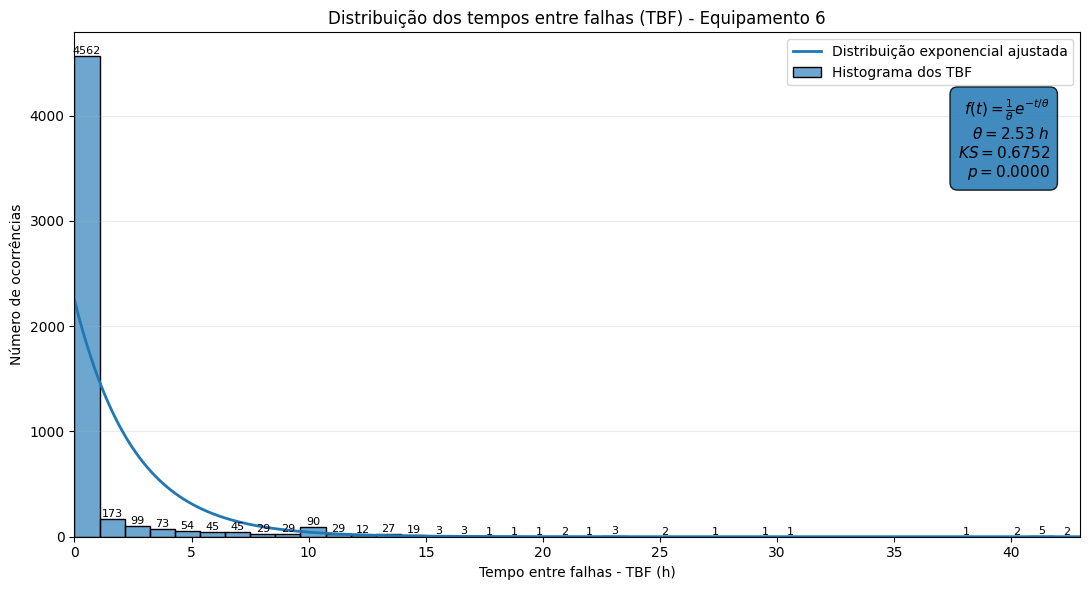


Equipamento: 7
Número de TBF: 1047
Parâmetro de escala da distribuição: 13.173 h
Locação: 0.000 min
Teste KS: estatística = 0.5055
Teste KS: p-valor = 0.0000
Resultado: o ajuste exponencial é rejeitado ao nível de significância de 5%.


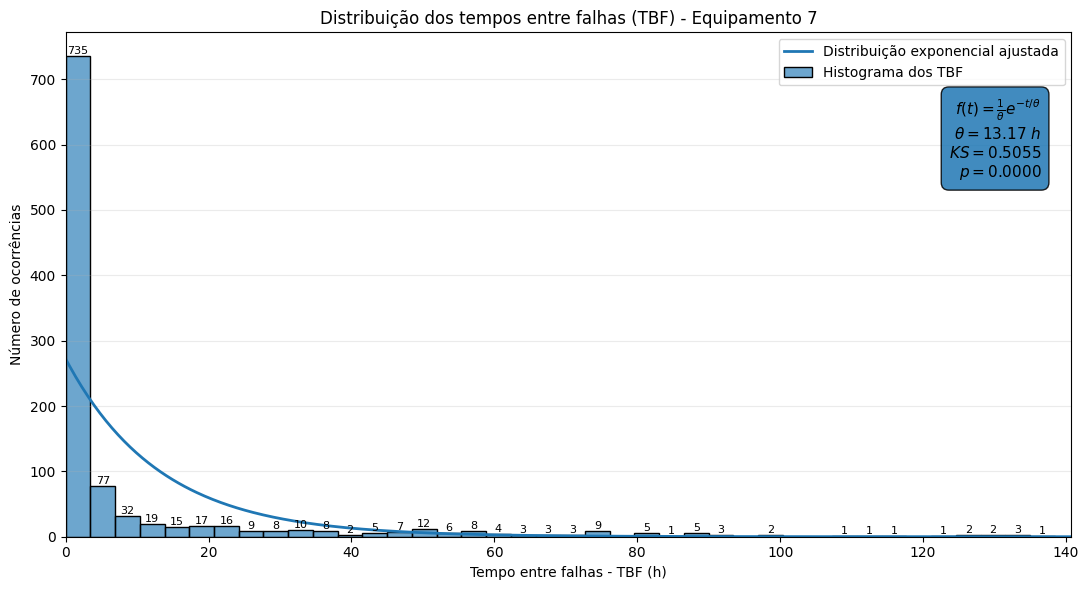


Equipamento: 8
Número de TBF: 1071
Parâmetro de escala da distribuição: 12.873 h
Locação: 0.000 min
Teste KS: estatística = 0.4748
Teste KS: p-valor = 0.0000
Resultado: o ajuste exponencial é rejeitado ao nível de significância de 5%.


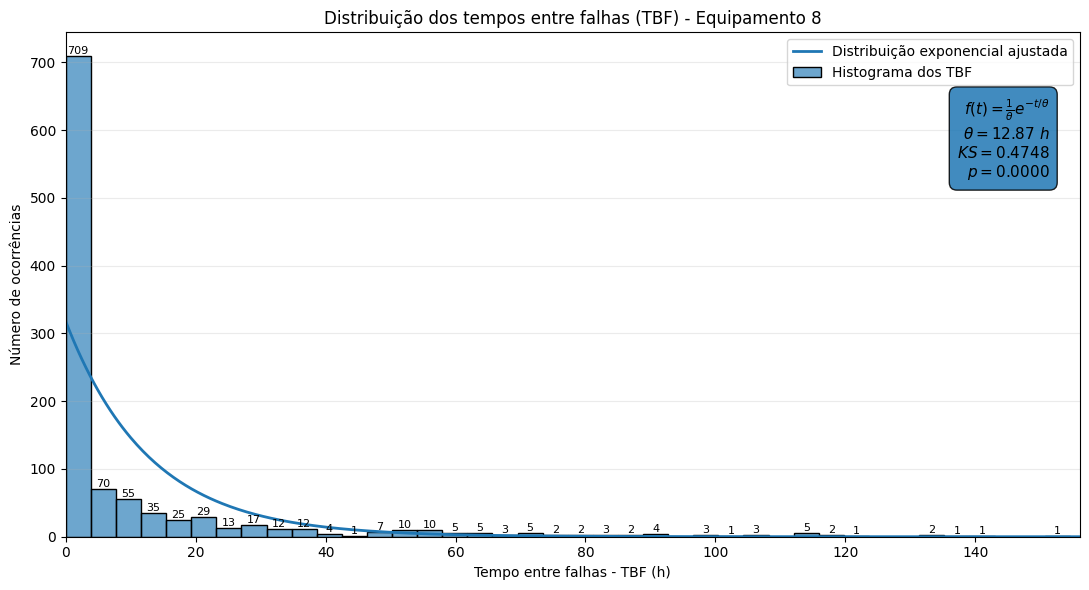

In [ ]:
# ============================================================
# DISTRIBUIÇÃO DOS TBF POR EQUIPAMENTO
# Ajuste da distribuição exponencial
#
# IMPORTANTE:
# O parâmetro do ajuste da PDF é apresentado apenas como
# parâmetro da distribuição ajustada.
#
# Ele NÃO é utilizado aqui para calcular MTBF ou R(t).
# ============================================================

for asset, group in valid_tbf.groupby("asset"):

    # --------------------------------------------------------
    # TBF do equipamento
    # --------------------------------------------------------

    tbf_asset = group["tbf_min"].dropna()

    if len(tbf_asset) < 5:
        print(
            f"{asset}: quantidade insuficiente de TBF "
            "para realizar o ajuste."
        )
        continue

    # --------------------------------------------------------
    # Ajuste da distribuição exponencial
    # --------------------------------------------------------

    loc, scale = stats.expon.fit(
        tbf_asset,
        floc=0
    )

    # Conversão do parâmetro de escala para horas
    scale_h = scale / 60

    # --------------------------------------------------------
    # Teste de aderência Kolmogorov-Smirnov
    # --------------------------------------------------------

    ks_stat, ks_p = stats.kstest(
        tbf_asset,
        "expon",
        args=(loc, scale)
    )

    # --------------------------------------------------------
    # Informações do ajuste
    # --------------------------------------------------------

    print("\n" + "=" * 60)
    print(f"Equipamento: {asset}")
    print("=" * 60)

    print(f"Número de TBF: {len(tbf_asset)}")
    print(f"Parâmetro de escala da distribuição: {scale_h:.3f} h")
    print(f"Locação: {loc:.3f} min")

    print(
        f"Teste KS: estatística = {ks_stat:.4f}"
    )

    print(
        f"Teste KS: p-valor = {ks_p:.4f}"
    )

    if ks_p >= 0.05:
        print(
            "Resultado: não há evidência suficiente para "
            "rejeitar o ajuste exponencial (α = 0,05)."
        )
    else:
        print(
            "Resultado: o ajuste exponencial é rejeitado "
            "ao nível de significância de 5%."
        )

    # --------------------------------------------------------
    # Dados utilizados apenas para visualização
    #
    # O ajuste estatístico continua utilizando TODOS os TBF.
    # --------------------------------------------------------

    x_max = tbf_asset.quantile(0.99)

    tbf_plot = tbf_asset[
        tbf_asset <= x_max
    ] / 60

    # --------------------------------------------------------
    # Histograma
    # --------------------------------------------------------

    plt.figure(figsize=(11, 6))

    ax = sns.histplot(
        tbf_plot,
        bins=40,
        stat="count",
        alpha=0.65,
        label="Histograma dos TBF"
    )

    # --------------------------------------------------------
    # PDF exponencial ajustada
    # --------------------------------------------------------

    x = np.linspace(
        0,
        x_max / 60,
        500
    )

    pdf = stats.expon.pdf(
        x,
        loc=0,
        scale=scale_h
    )

    # Conversão da densidade para escala de contagem
    bin_width = ax.patches[0].get_width()

    pdf_count = (
        pdf
        * len(tbf_plot)
        * bin_width
    )

    plt.plot(
        x,
        pdf_count,
        linewidth=2,
        label="Distribuição exponencial ajustada"
    )

    # --------------------------------------------------------
    # Valores das barras
    # --------------------------------------------------------

    for bar in ax.patches:

        height = bar.get_height()

        if height > 0:

            ax.text(
                bar.get_x() + bar.get_width() / 2,
                height,
                f"{int(height)}",
                ha="center",
                va="bottom",
                fontsize=8
            )

    # --------------------------------------------------------
    # Equação da PDF e parâmetro do ajuste
    # --------------------------------------------------------

    equation = (
        r"$f(t)=\frac{1}{\theta}e^{-t/\theta}$"
        "\n"
        rf"$\theta={scale_h:.2f}\ h$"
        "\n"
        rf"$KS={ks_stat:.4f}$"
        "\n"
        rf"$p={ks_p:.4f}$"
    )

    plt.text(
        0.97,
        0.87,
        equation,
        transform=plt.gca().transAxes,
        fontsize=11,
        verticalalignment="top",
        horizontalalignment="right",
        bbox=dict(
            boxstyle="round,pad=0.5",
            alpha=0.85
        )
    )

    # --------------------------------------------------------
    # Configuração do gráfico
    # --------------------------------------------------------

    plt.title(
        f"Distribuição dos tempos entre falhas (TBF) - Equipamento {asset}"
    )

    plt.xlabel(
        "Tempo entre falhas - TBF (h)"
    )

    plt.ylabel(
        "Número de ocorrências"
    )

    plt.xlim(
        0,
        x_max / 60
    )

    plt.grid(
        axis="y",
        alpha=0.25
    )

    plt.legend(
        loc="upper right"
    )

    plt.tight_layout()
    plt.show()

## 12. Ajuste de Weibull por equipamento

O parâmetro de forma `β` será utilizado como indicador exploratório da tendência da taxa de falha:

- β < 1: tendência decrescente;
- β ≈ 1: aproximadamente constante;
- β > 1: tendência crescente.

A interpretação deve considerar o número de observações disponíveis.

,asset,n_TBF,beta_shape,eta_scale_h,failure_rate_trend
1,1,1260,0.3329,1.3055,Decrescente
6,6,5370,0.3617,0.2256,Decrescente
4,4,2146,0.3719,1.0849,Decrescente
8,8,1071,0.3727,3.0794,Decrescente
5,5,63,0.3941,23.0377,Decrescente
3,3,2946,0.4012,0.9983,Decrescente
7,7,1047,0.4053,3.2622,Decrescente
2,2,16527,0.4413,0.1230,Decrescente
0,0,4419,0.4479,0.7223,Decrescente


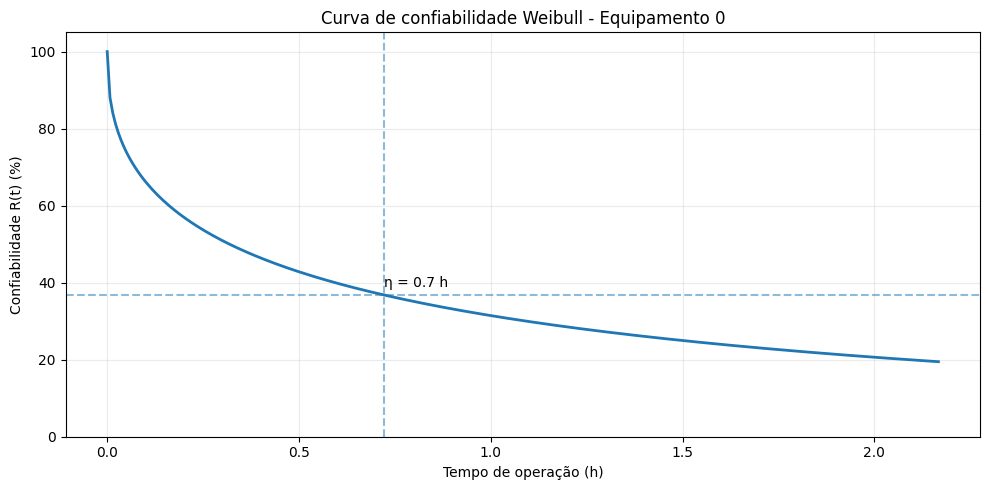

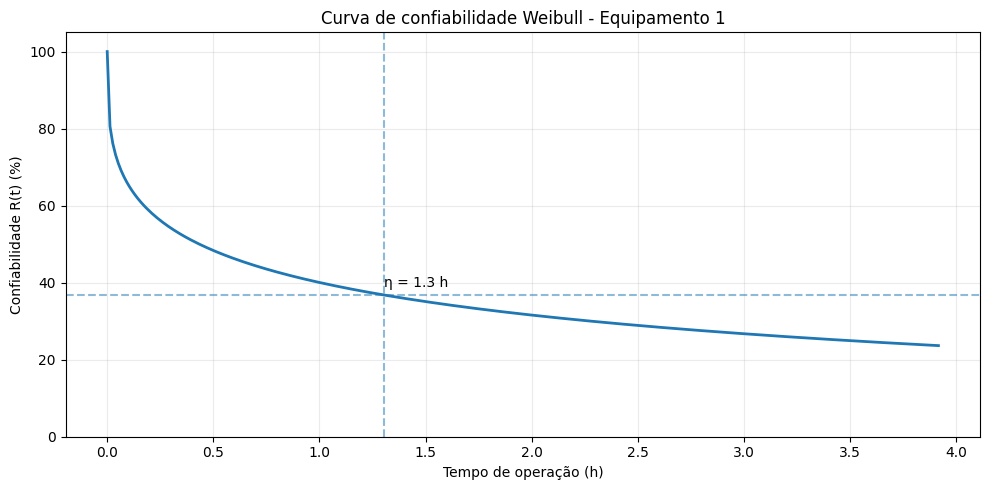

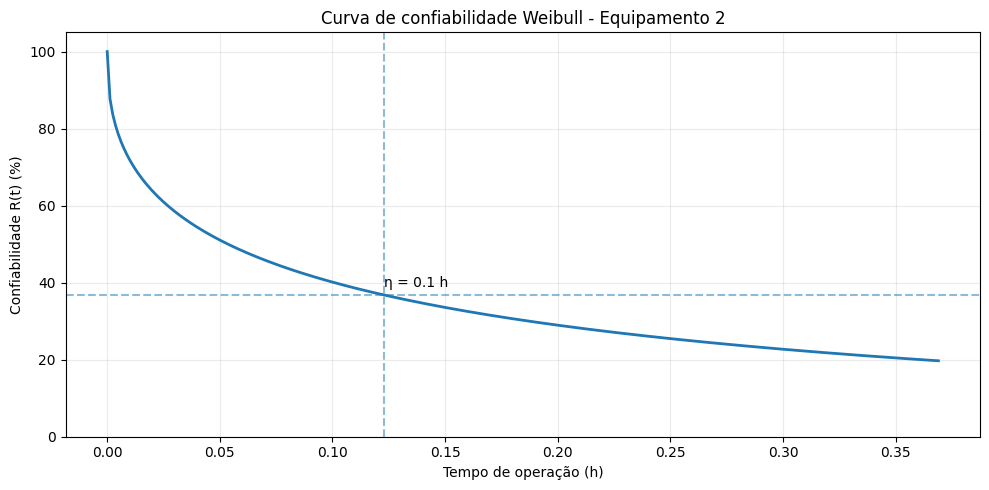

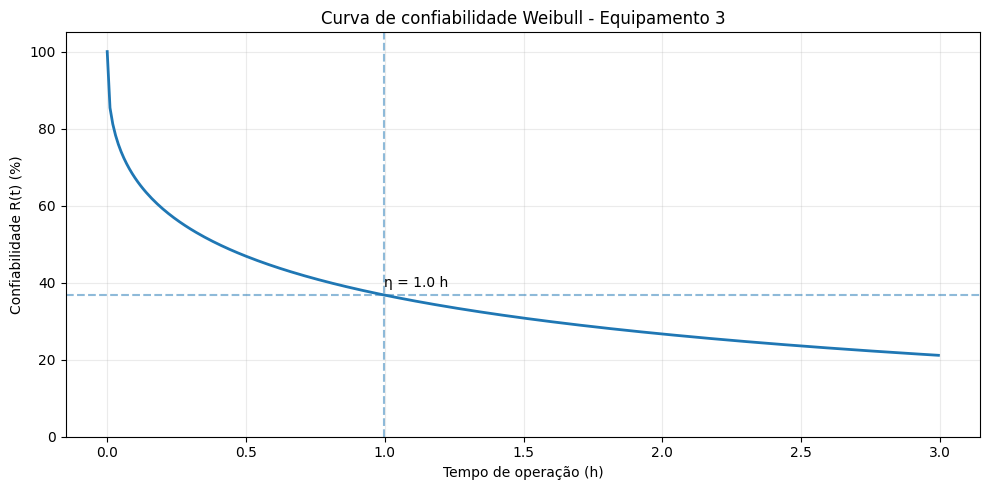

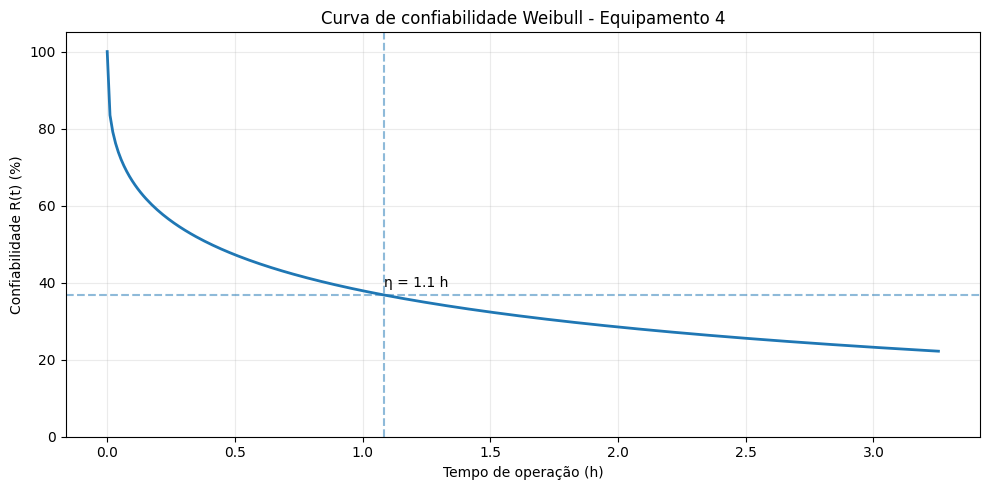

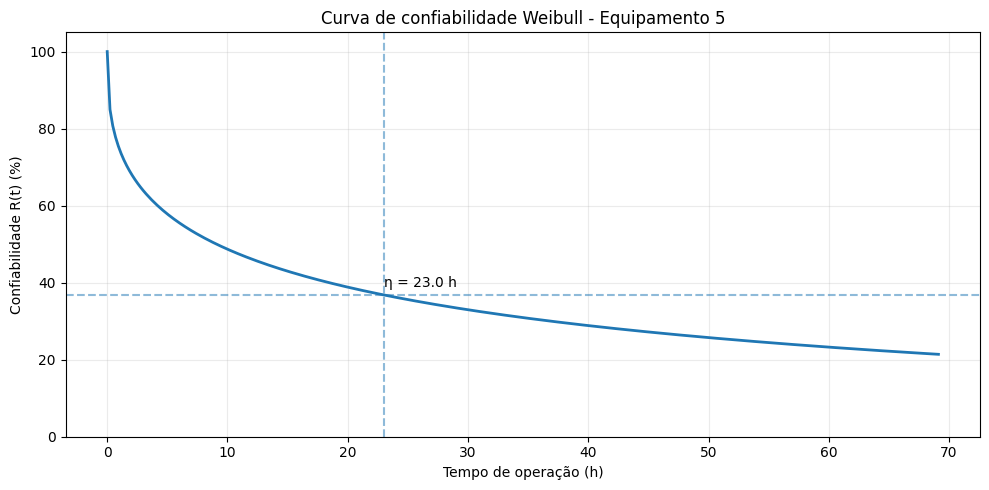

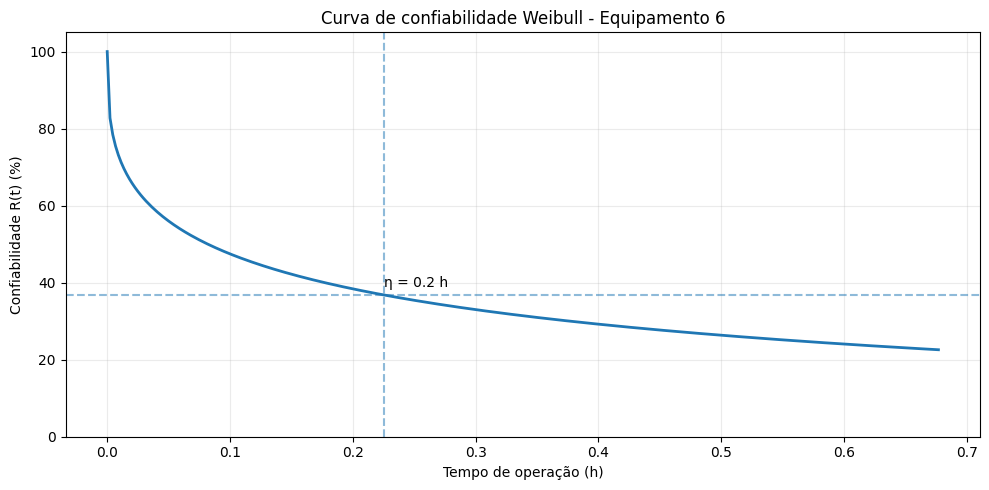

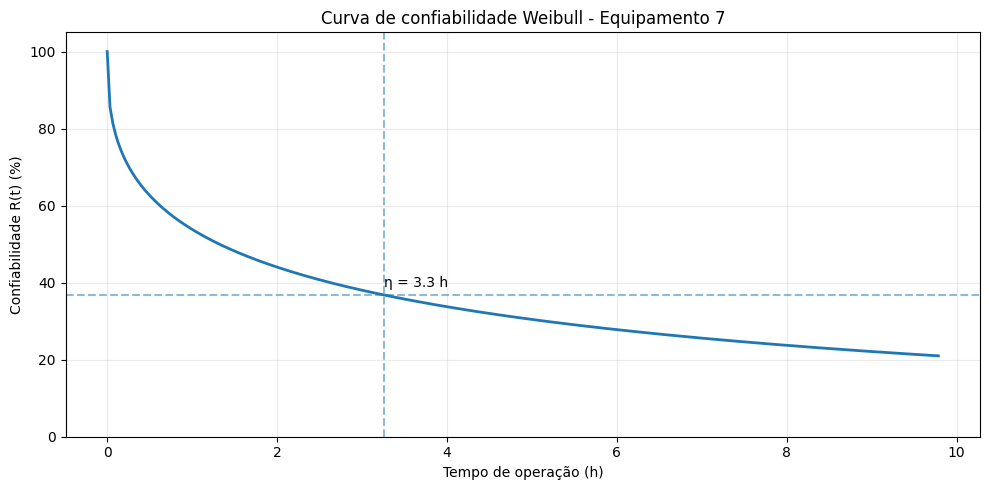

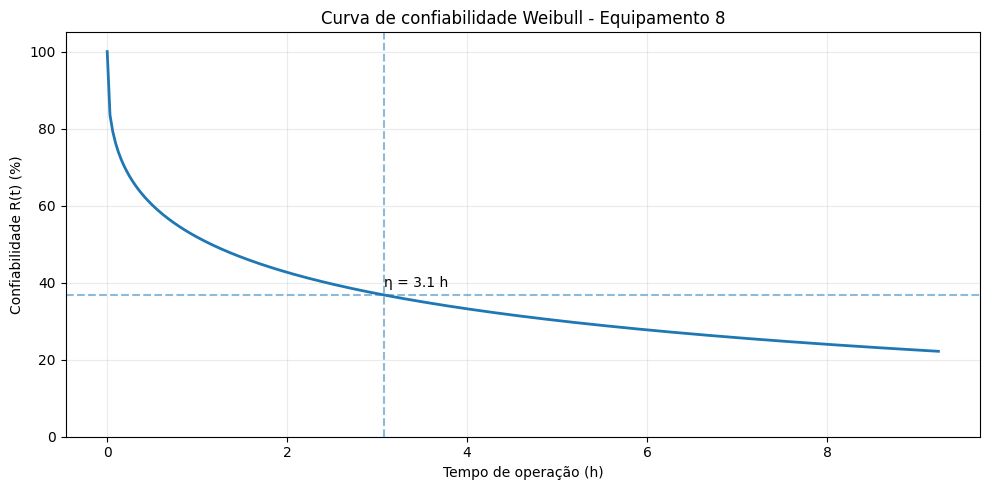

In [ ]:
weibull_rows = []

for asset, group in valid_tbf.groupby("asset"):
    values = group["tbf_min"].dropna()

    if len(values) >= 5 and np.all(values > 0):
        beta, loc, eta = stats.weibull_min.fit(
            values,
            floc=0
        )

        weibull_rows.append({
            "asset": asset,
            "n_TBF": len(values),
            "beta_shape": beta,
            "eta_scale_h": eta / 60
        })

weibull = pd.DataFrame(weibull_rows)

if len(weibull):

    weibull["failure_rate_trend"] = np.select(
        [
            weibull["beta_shape"] < 0.9,
            weibull["beta_shape"] <= 1.1,
            weibull["beta_shape"] > 1.1
        ],
        [
            "Decrescente",
            "Aproximadamente constante",
            "Crescente"
        ],
        default="Não classificado"
    )

    display(
        weibull.sort_values("beta_shape")
    )

else:
    print(
        "Não houve ativos com quantidade suficiente de TBF."
    )
    
# =========================================================
# 7. CURVA DE CONFIABILIDADE WEIBULL
# =========================================================

if len(weibull):

    # Criar uma figura para cada equipamento
    for _, row in weibull.iterrows():

        asset = row["asset"]
        beta = row["beta_shape"]
        eta = row["eta_scale_h"]

        # Faixa de tempo para a curva
        t = np.linspace(0, eta * 3, 300)

        # Função de confiabilidade Weibull
        reliability = np.exp(
            -((t / eta) ** beta)
        )

        # Converter para porcentagem
        reliability_pct = reliability * 100

        # -----------------------------------------------------
        # Plot
        # -----------------------------------------------------
        plt.figure(figsize=(10, 5))

        plt.plot(
            t,
            reliability_pct,
            linewidth=2
        )

        # Linha de referência de 63,2%
        plt.axhline(
            36.8,
            linestyle="--",
            alpha=0.5
        )

        # Linha vertical em eta
        plt.axvline(
            eta,
            linestyle="--",
            alpha=0.5
        )

        # -----------------------------------------------------
        # Informações da curva
        # -----------------------------------------------------
        plt.text(
            eta,
            38,
            f"η = {eta:.1f} h",
            ha="left",
            va="bottom"
        )

        plt.title(
            f"Curva de confiabilidade Weibull - Equipamento {asset}"
        )

        plt.xlabel("Tempo de operação (h)")
        plt.ylabel("Confiabilidade R(t) (%)")

        plt.ylim(0, 105)
        plt.grid(alpha=0.25)

        plt.tight_layout()
        plt.show()

else:

    print(
        "Não há parâmetros Weibull disponíveis para gerar as curvas."
    )
    


## 13. Priorização e Análise de Criticidade dos Equipamentos

### 13.1 Fundamentação teórica

A priorização dos equipamentos será realizada por meio de uma abordagem quantitativa baseada em indicadores históricos de falhas e manutenção, complementada pela Manutenção Centrada em Confiabilidade (RCM). Segundo Moubray (1997), a RCM considera as funções dos ativos, as falhas funcionais, os modos de falha, seus efeitos e consequências para orientar a seleção de estratégias de manutenção. Jardine, Lin e Banjevic (2006) estruturam a manutenção baseada em condição nas etapas de aquisição de dados, processamento e tomada de decisão, enquanto Pintelon e Gelders (1992) abordam a estruturação das decisões e políticas de gestão da manutenção.

Como suporte à priorização, Antosz e Ratnayake (2016), Mendonça et al. (2018) e Attanayake, Chandima e Markeset (2024) apresentam abordagens multicritério aplicadas à classificação de máquinas, à priorização de equipamentos e à avaliação da criticidade de falhas. Neste estudo, será utilizada uma soma ponderada de indicadores normalizados, como uma adaptação metodológica simplificada, sem reproduzir integralmente os métodos AHP ou PROMETHEE II.

### 13.2 Critérios de priorização

Serão considerados dois critérios:

- **Frequência de falhas:** quantidade de eventos de alarme identificados para cada equipamento no período analisado.
- **Tempo acumulado em alarme:** soma das durações estimadas dos eventos de alarme associados a cada equipamento.

A frequência permite identificar equipamentos com eventos recorrentes, enquanto o tempo acumulado em alarme evidencia aqueles associados a períodos mais prolongados de interrupção. A utilização conjunta dos critérios permite considerar tanto a recorrência quanto a duração dos eventos.

> **Limitação dos dados:** um evento de alarme não representa necessariamente uma falha física, e sua duração não corresponde obrigatoriamente ao tempo efetivo de reparo. Por isso, os resultados serão interpretados como indicadores operacionais de priorização, sujeitos às limitações da base de dados.

### 13.3 Normalização dos indicadores

Como os critérios possuem escalas diferentes, será aplicada a normalização Min-Max, que transforma os valores para uma escala entre 0 e 1:

$$
x_i^* = \frac{x_i-x_{\min}}{x_{\max}-x_{\min}}
$$

Em que:

- $x_i$: valor do indicador para o equipamento $i$;
- $x_{\min}$: menor valor observado entre os equipamentos;
- $x_{\max}$: maior valor observado entre os equipamentos;
- $x_i^*$: valor normalizado do indicador.

Quando todos os equipamentos apresentarem o mesmo valor para determinado critério, será atribuído o valor neutro de 0,5, uma vez que esse indicador não permite diferenciá-los.

### 13.4 Cálculo do índice de priorização

O índice será calculado por meio de uma soma ponderada dos critérios normalizados:

$$
S_i = 100\left(0{,}5F_i^*+0{,}5D_i^*\right)
$$

Em que:

- $S_i$: índice de priorização do equipamento $i$, variando de 0 a 100;
- $F_i^*$: frequência de eventos de alarme normalizada;
- $D_i^*$: tempo acumulado em alarme normalizado;
- $0{,}5$: peso atribuído a cada critério.

Os pesos iguais constituem uma escolha metodológica inicial deste estudo, e não valores extraídos diretamente das referências bibliográficas. Essa definição poderá ser aprimorada futuramente por meio de consulta a especialistas e aplicação formal do método AHP.

A disponibilidade não será incluída separadamente nesta versão do índice, pois pode apresentar redundância com o tempo de alarme, dependendo de como foi calculada. Essa decisão busca evitar a atribuição de peso excessivo a informações correlacionadas.

### 13.5 Classificação dos equipamentos

Após o cálculo, os equipamentos serão ordenados em ordem decrescente de índice e classificados em três níveis:

| Índice de priorização | Classificação |
|:--|:--|
| $S_i \leq 33{,}33$ | Baixa |
| $33{,}33 < S_i \leq 66{,}67$ | Média |
| $S_i > 66{,}67$ | Alta |

Os limites são convenções adotadas para facilitar a interpretação dos resultados, não valores universais estabelecidos pelas referências. As classes representam a prioridade relativa dos equipamentos dentro do conjunto analisado.

### 13.6 Utilização dos resultados na RCM

O ranking será utilizado como etapa inicial de triagem para selecionar os equipamentos que serão investigados com maior profundidade. Para esses ativos, a análise RCM deverá considerar suas funções, falhas funcionais, modos de falha, efeitos e consequências, permitindo avaliar estratégias de manutenção adequadas às condições operacionais.

Dessa forma, a priorização quantitativa organiza os equipamentos com base nos dados históricos disponíveis, enquanto a RCM complementa a análise com a avaliação funcional e das consequências das falhas. O objetivo é direcionar os esforços de manutenção para os ativos que apresentem maior necessidade de investigação, sem considerar o índice isoladamente como uma avaliação completa de criticidade.

In [ ]:

# ============================================================
# 8. Equipment prioritization based on historical indicators
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

# Initial criterion weights.
# These are methodological choices, not weights copied from
# the cited papers. They can later be replaced by AHP weights.
WEIGHT_FAILURES = 0.50
WEIGHT_ALARM_DURATION = 0.50

# Check that the required KPI columns are available.
required_columns = {
    "asset",
    "failures",
    "total_alarm_min",
    "Availability_%"
}

missing_columns = required_columns.difference(kpi.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns in kpi: {sorted(missing_columns)}"
    )

if not np.isclose(
    WEIGHT_FAILURES + WEIGHT_ALARM_DURATION, 1.0
):
    raise ValueError("Criterion weights must sum to 1.0.")

# Keep one row per asset and prepare the ranking dataset.
crit = kpi.copy()

if crit["asset"].duplicated().any():
    raise ValueError(
        "The KPI table contains duplicate assets. "
        "Aggregate the data before calculating the ranking."
    )

for col in ["failures", "total_alarm_min", "Availability_%"]:
    crit[col] = pd.to_numeric(crit[col], errors="coerce")

# Min-Max normalization.
# If a criterion has no variation, assign a neutral value.
def minmax_normalize(series):
    values = pd.to_numeric(series, errors="coerce")
    valid = values.dropna()

    result = pd.Series(np.nan, index=series.index, dtype=float)

    if valid.empty:
        return result.fillna(0.5)

    minimum = valid.min()
    maximum = valid.max()

    if np.isclose(maximum, minimum):
        result.loc[valid.index] = 0.5
    else:
        result.loc[valid.index] = (
            (valid - minimum) / (maximum - minimum)
        )

    return result.fillna(0.5)

# Normalize the two selected criteria.
crit["score_failures"] = minmax_normalize(
    crit["failures"]
)

crit["score_alarm_duration"] = minmax_normalize(
    crit["total_alarm_min"]
)

# Weighted prioritization score, from 0 to 100.
crit["priority_score"] = 100 * (
    WEIGHT_FAILURES * crit["score_failures"]
    + WEIGHT_ALARM_DURATION * crit["score_alarm_duration"]
)

# Relative priority classes.
crit["priority_class"] = pd.cut(
    crit["priority_score"],
    bins=[-np.inf, 33.33, 66.67, np.inf],
    labels=["Baixa", "Média", "Alta"],
    right=True
)

# Sort from highest to lowest priority.
crit = crit.sort_values(
    ["priority_score", "failures", "total_alarm_min"],
    ascending=[False, False, False]
).reset_index(drop=True)

crit.insert(0, "priority_rank", np.arange(1, len(crit) + 1))

# Select and order output columns.
ranking_columns = [
    "priority_rank",
    "asset",
    "failures",
    "total_alarm_min",
    "MTBF_h",
    "MTTR_h",
    "Availability_%",
    "score_failures",
    "score_alarm_duration",
    "priority_score",
    "priority_class"
]

# Keep only columns that exist in the KPI table or were created above.
ranking_columns = [
    col for col in ranking_columns if col in crit.columns
]

ranking = crit[ranking_columns].copy()

# Export the results.
output_dir = Path("resultados_tcc")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "ranking_priorizacao_equipamentos.csv"
ranking.to_csv(output_file, index=False, encoding="utf-8-sig")

# Display results.
display(ranking)

print(f"Ranking exported to: {output_file.resolve()}")
print(f"Number of ranked assets: {len(ranking)}")

,priority_rank,asset,failures,total_alarm_min,Availability_%,score_failures,score_alarm_duration,priority_score,priority_class
0,1,0,4420,"180,336.7833",81.9668,0.2646,1.0000,63.2289,Média
1,2,2,16528,"33,509.2500",96.0652,1.0000,0.1826,59.1320,Média
2,3,1,1261,"158,924.5500",83.7829,0.0727,0.8808,47.6753,Média
3,4,6,5371,"10,819.3500",98.6925,0.3223,0.0563,18.9335,Baixa
4,5,3,2947,"2,218.7667",99.7295,0.1751,0.0085,9.1781,Baixa
5,6,4,2147,"10,131.0167",98.7732,0.1265,0.0525,8.9509,Baixa
6,7,7,1048,981.6500,99.8816,0.0598,0.0016,3.0666,Baixa
7,8,8,1072,700.3167,99.9155,0.0612,0.0000,3.0612,Baixa
8,9,5,64,"6,711.0333",98.9962,0.0000,0.0335,1.6730,Baixa


Ranking exported to: C:\Users\Keslley\Downloads\resultados_tcc\ranking_priorizacao_equipamentos.csv
Number of ranked assets: 9


## 14. Detecção exploratória de anomalias

Um Isolation Forest é utilizado para encontrar registros operacionalmente atípicos usando potência, tempo de ciclo e produção.

Isso **não é um modelo supervisionado de previsão de falhas**. É uma etapa exploratória para apoiar uma futura estratégia baseada em condição.

In [ ]:
from sklearn.ensemble import IsolationForest

model_cols = [
    c for c in ["power_avg", "cycle_time", "items"]
    if c in df.columns
]

model_data = (
    df[model_cols]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

if len(model_data) >= 100:
    sample_n = min(100_000, len(model_data))
    sample = model_data.sample(sample_n, random_state=42).copy()

    iso = IsolationForest(
        contamination=0.01,
        random_state=42,
        n_jobs=-1
    )

    sample["anomaly"] = iso.fit_predict(sample[model_cols])

    print("Amostra analisada:", len(sample))
    print("Anomalias:", (sample["anomaly"] == -1).sum())
    display(sample.head())
else:
    print("Dados insuficientes para detecção de anomalias.")

Amostra analisada: 100000
Anomalias: 846


,power_avg,cycle_time,items,anomaly
1337907,0.0000,0.0000,0.0000,1
990969,2.0000,60.0000,6.0000,1
1501399,0.0000,0.0000,0.0000,1
650633,2.0000,60.0000,6.0000,1
1084889,3.0000,0.0000,0.0000,1


## 15. Ranking para priorização de manutenção

In [ ]:
ranking = crit[
    ["asset", "failures", "MTBF_min", "MTTR_min",
     "total_alarm_min", "Availability_%",
     "criticality_score_0_100", "criticality_class"]
].copy()

ranking = ranking.rename(
    columns={"criticality_score_0_100": "priority_score"}
)

ranking = ranking.sort_values(
    "priority_score", ascending=False
).reset_index(drop=True)

ranking.index = ranking.index + 1
display(ranking)

,asset,failures,MTBF_min,MTTR_min,total_alarm_min,Availability_%,priority_score,criticality_class
1,0,4420,185.4926,40.8094,"180,336.7833",81.9668,70.5831,Alta
2,1,1261,651.6323,126.1306,"158,924.5500",83.7829,56.1166,Média
3,2,16528,49.4980,2.0274,"33,509.2500",96.0652,51.5960,Média
4,6,5371,152.0543,2.0144,"10,819.3500",98.6925,16.5095,Baixa
5,4,2147,379.9184,4.7187,"10,131.0167",98.7732,8.4335,Baixa
6,3,2947,277.5622,0.7529,"2,218.7667",99.7295,7.5498,Baixa
7,7,1048,790.3557,0.9367,981.6500,99.8816,2.4911,Baixa
8,8,1072,772.4077,0.6533,700.3167,99.9155,2.4490,Baixa
9,5,64,"10,341.4161",104.8599,"6,711.0333",98.9962,2.3628,Baixa


## 16. Exportação dos resultados

Os resultados são exportados em CSV para posterior uso no Power BI, Excel ou na elaboração das tabelas do TCC.

In [ ]:
OUTPUT_DIR = "resultados_tcc"
os.makedirs(OUTPUT_DIR, exist_ok=True)

kpi.to_csv(
    f"{OUTPUT_DIR}/indicadores_confiabilidade.csv",
    index=False
)

events.to_csv(
    f"{OUTPUT_DIR}/eventos_falha.csv",
    index=False
)

ranking.to_csv(
    f"{OUTPUT_DIR}/ranking_criticidade.csv",
    index=False
)

if len(weibull):
    weibull.to_csv(
        f"{OUTPUT_DIR}/weibull_por_equipamento.csv",
        index=False
    )

if len(pre_failure):
    pre_failure.to_csv(
        f"{OUTPUT_DIR}/janelas_pre_falha.csv",
        index=False
    )

print(f"Resultados exportados para: {OUTPUT_DIR}/")

Resultados exportados para: resultados_tcc/


## 17. Checklist para o TCC

Ao executar o notebook, registre:

1. período e quantidade de dados;
2. quantidade de máquinas;
3. quantidade de eventos;
4. MTBF por ativo;
5. MTTR aproximado por ativo;
6. disponibilidade;
7. ranking de criticidade;
8. distribuição dos TBF;
9. parâmetros de Weibull;
10. possíveis sinais antecedentes;
11. limitações da base;
12. estratégias de manutenção propostas.

### Cuidados metodológicos

- Não chamar automaticamente todo estado 3 de falha física.
- Não tratar a duração do alarme como MTTR real sem ressalva.
- Não afirmar causalidade apenas por correlação.
- Validar os ativos críticos com conhecimento de processo.
- Registrar as decisões de limpeza e tratamento de outliers.

## 18. Referências do projeto

As referências já selecionadas para o TCC incluem Birolini, Moubray, Jardine et al., Nakajima, Hansen, ABNT NBR 5462, ISO 14224 e IEC 60300-3-11.

**Dataset:** Atzeni et al. (2023), *Data-Driven Insights through Industrial Retrofitting: An Anonymized Dataset with Machine Learning Use Cases*, Sensors, 23(13), 6078.

O repositório oficial disponibiliza os dados da Company A e Company B.